# Multi-Asset Comparative Evolution: True Close Price vs. Predicted Price (Gold, Bitcoin & Crude Oil)
**Dataset Horizon:** `01-01-2019` to `31-12-2023` (Chronological 70% Train / 15% Validation / 15% Out-of-Sample Test Split)

This notebook compares the out-of-sample price predictions, missingness robustness ($\eta \in [0.1, 0.9]$), and learned dynamic gating weights $\mathbf{W}^{(t)}$ across **Gold**, **Bitcoin (BTC)**, and **Crude Oil** for:
1. **`Adaptive_Level_II (Proposed)`**: Level II Intermediate Fusion with DAIN, FinBERT + DistilBERT (`max_length=256`), Evidential Dynamic Softmax Gating, and LoRA ($r=1$).
2. **`Static_Early_Fusion (Level I)`**: Concatenation baseline with zero-imputation.
3. **`Single_Modality_LSTM (Price Only)`**: Unimodal 8-feature OHLCV + technical indicator LSTM control.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

all_metrics_df = pd.read_csv('results/all_assets_benchmark_metrics.csv')
print('=== Combined Multi-Asset 3-Model Benchmark Summary (eta in [0.1, 0.2, 0.5, 0.9]) ===')
print(all_metrics_df[all_metrics_df['Eta'].isin([0.1, 0.2, 0.5, 0.9])].to_string(index=False))

=== Combined Multi-Asset 3-Model Benchmark Summary (eta in [0.1, 0.2, 0.5, 0.9]) ===
          Asset                             Model  Eta  W_Price  W_Sentiment   W_News  W_Macro        RMSE         MAE  MAPE_Pct       R2    DA_Pct  CumReturn_Pct    Sharpe  MaxDD_Pct  Active_Trade_Ratio_Pct
           Gold      Adaptive_Level_II (Proposed)  0.1 0.570465     0.227153 0.195760 0.006622   26.059786   19.338674  0.981644 0.713607 52.432432       0.247677  0.086086   7.947614               86.486486
           Gold      Adaptive_Level_II (Proposed)  0.2 0.518306     0.249402 0.227884 0.004407   28.595213   21.832584  1.107006 0.655168 50.810811      -6.882891 -0.798229  14.601808               87.567568
           Gold      Adaptive_Level_II (Proposed)  0.5 0.348938     0.305718 0.334869 0.010474   34.837631   27.365653  1.388400 0.488179 51.351351      -2.850861 -0.289390  11.399717               89.189189
           Gold      Adaptive_Level_II (Proposed)  0.9 0.314064     0.326880 0.3562

---
## Gold: True Close Price vs. Predicted Price Evolution & Missingness Sweep
* **Predictions CSV:** `results/gold_test_predictions.csv`
* **Learned Gating Weights CSV:** `results/gold_gating_weights_W.csv`

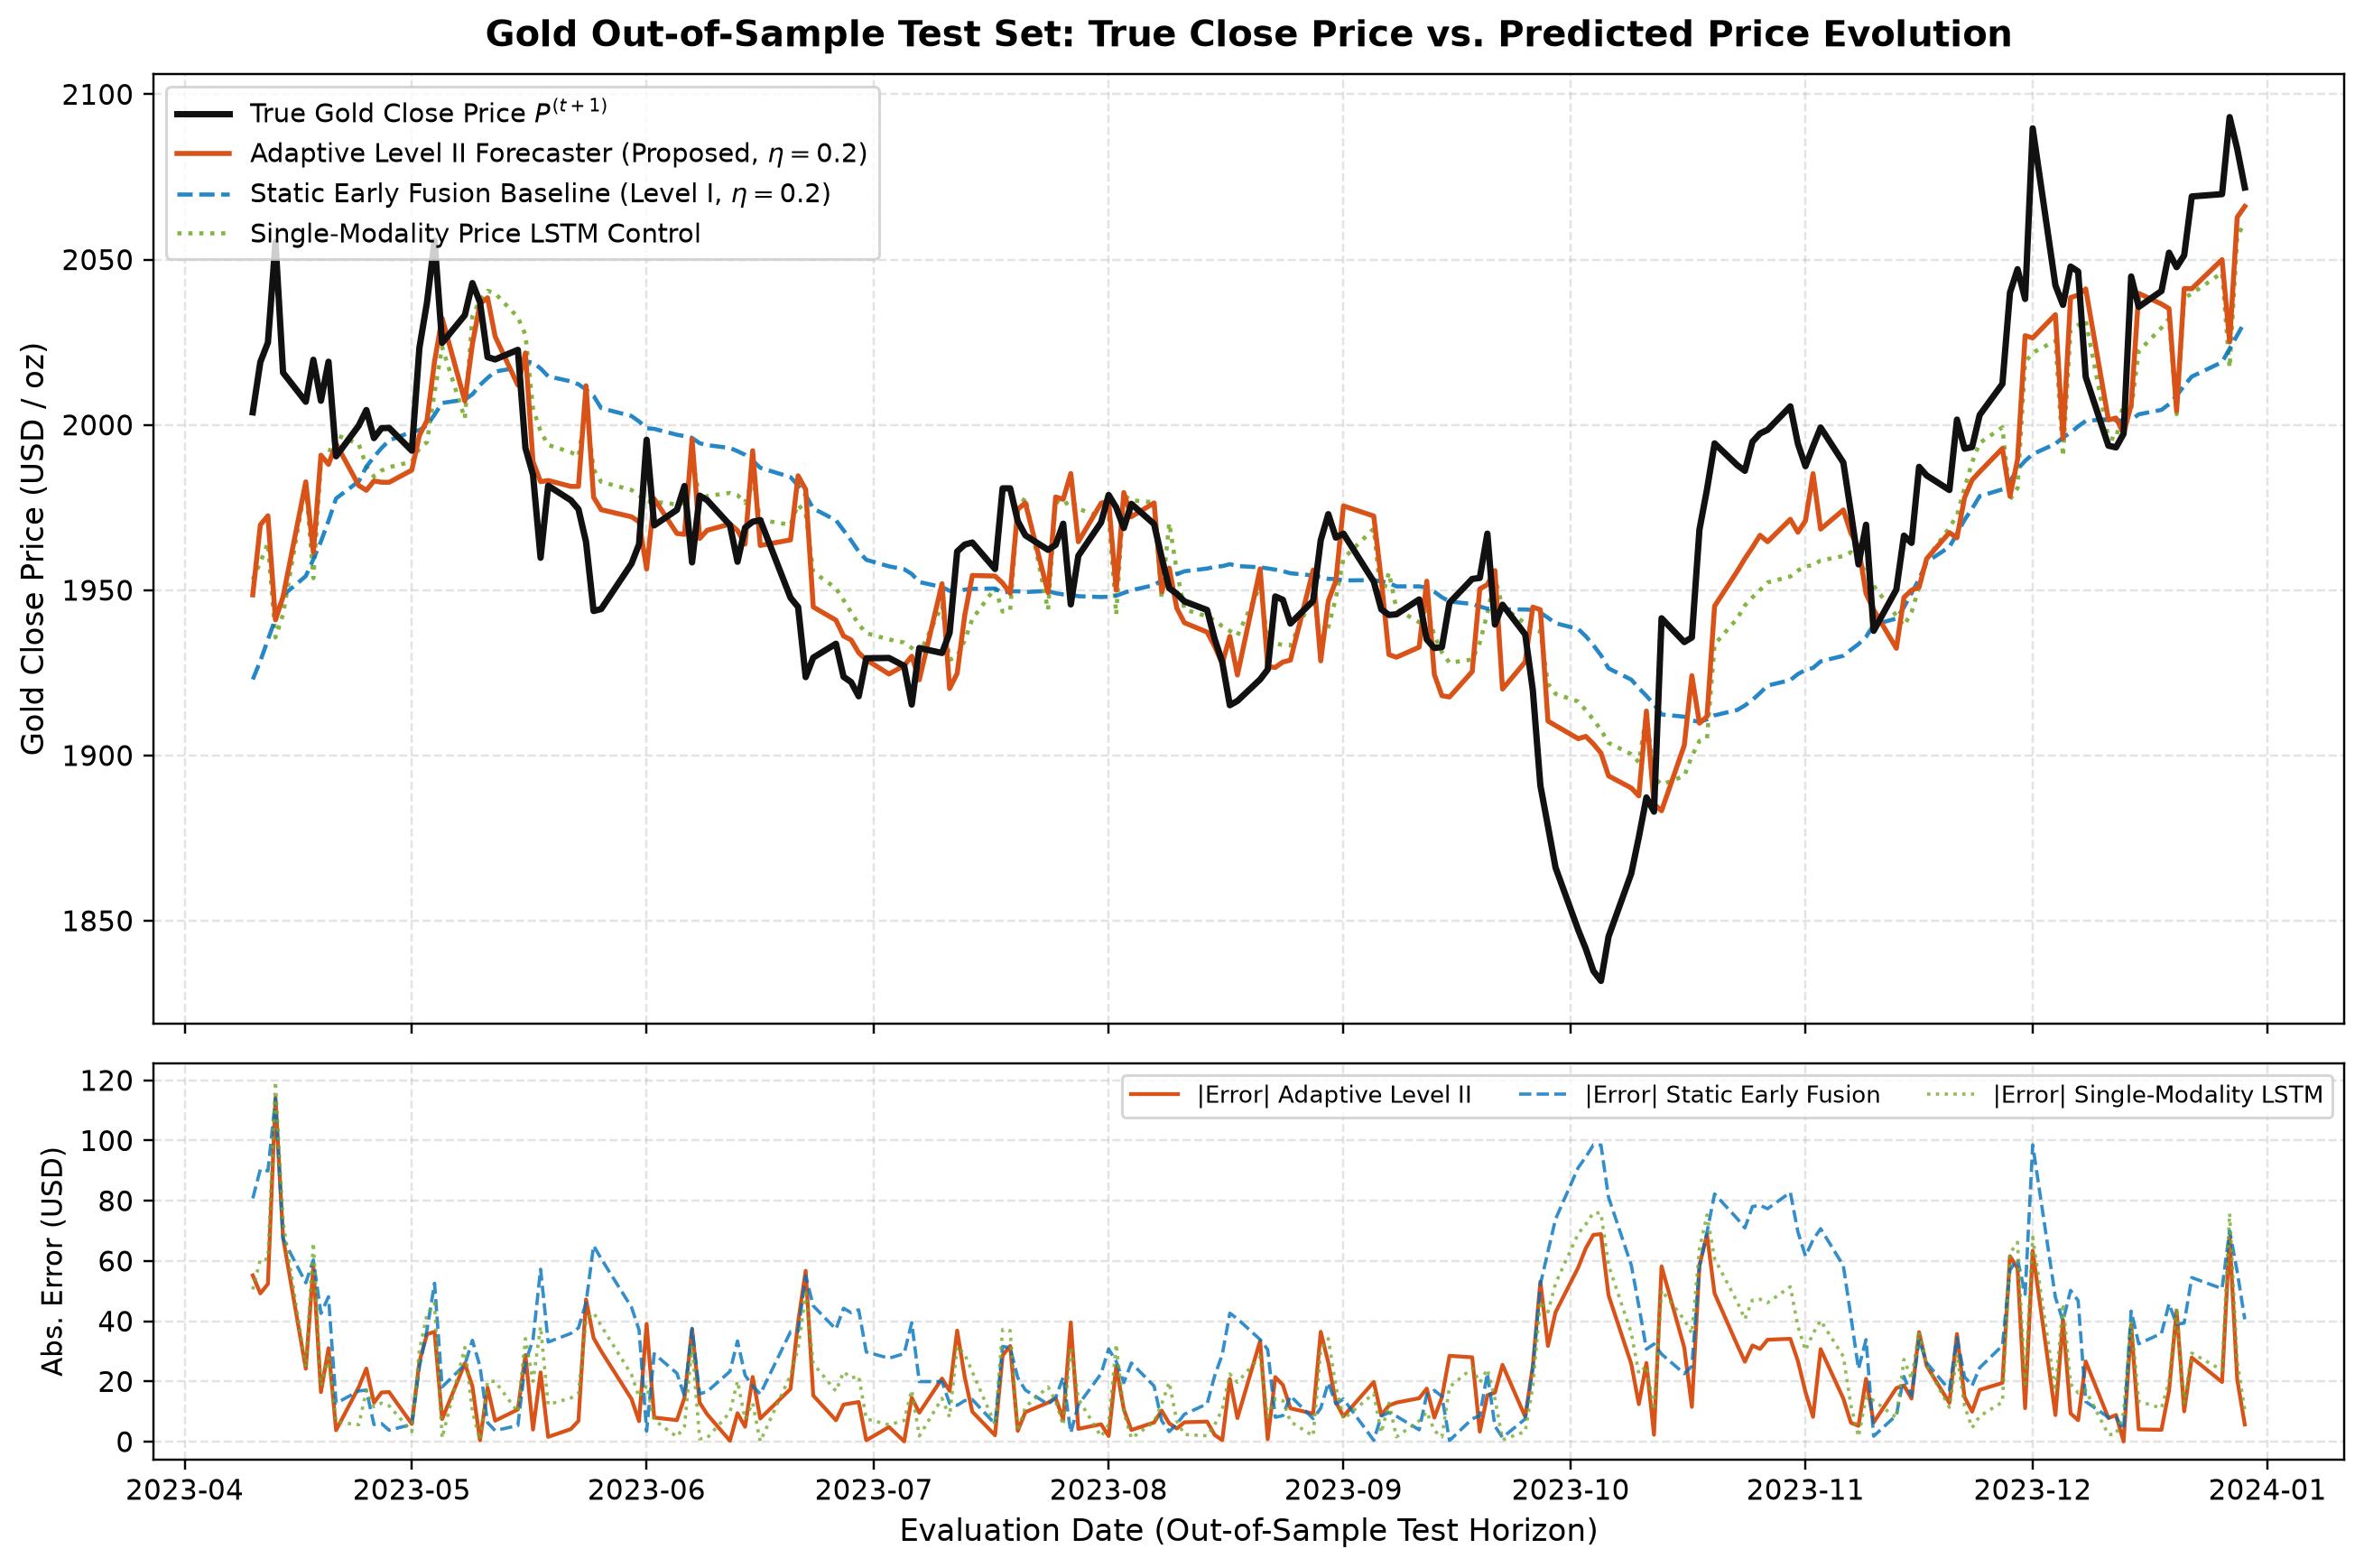

In [ ]:
# Gold: Plot Comparative Evolution of True Close Price vs. Predicted Price
pred_gold = pd.read_csv('results/gold_test_predictions.csv', parse_dates=['Date'])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [2.4, 1.0]}, sharex=True)
ax1.plot(pred_gold['Date'], pred_gold['True_Next_Close_P_t1'], label='True Gold Close Price P^(t+1)', color='#111111', linewidth=2.3)
ax1.plot(pred_gold['Date'], pred_gold['Pred_Adaptive_Level_II_eta02'], label='Adaptive Level II Forecaster (Proposed, eta=0.2)', color='#D95319', linewidth=1.8)
ax1.plot(pred_gold['Date'], pred_gold['Pred_Static_Early_Fusion_eta02'], label='Static Early Fusion Baseline (Level I, eta=0.2)', color='#0072BD', linewidth=1.5, linestyle='--')
ax1.plot(pred_gold['Date'], pred_gold['Pred_Single_Modality_LSTM_eta02'], label='Single-Modality Price LSTM Control', color='#77AC30', linewidth=1.5, linestyle=':')
ax1.set_title('Gold Out-of-Sample Test Set: True Close Price vs. Predicted Price Evolution', fontsize=13, fontweight='bold')
ax1.set_ylabel('Gold Close Price (USD / oz)'); ax1.grid(True, linestyle='--', alpha=0.35); ax1.legend(loc='upper left')

ax2.plot(pred_gold['Date'], (pred_gold['Pred_Adaptive_Level_II_eta02'] - pred_gold['True_Next_Close_P_t1']).abs(), label='|Error| Adaptive Level II', color='#D95319')
ax2.plot(pred_gold['Date'], (pred_gold['Pred_Static_Early_Fusion_eta02'] - pred_gold['True_Next_Close_P_t1']).abs(), label='|Error| Static Early Fusion', color='#0072BD', linestyle='--')
ax2.plot(pred_gold['Date'], (pred_gold['Pred_Single_Modality_LSTM_eta02'] - pred_gold['True_Next_Close_P_t1']).abs(), label='|Error| Single-Modality LSTM', color='#77AC30', linestyle=':')
ax2.set_ylabel('Abs. Error (USD)'); ax2.set_xlabel('Evaluation Date'); ax2.grid(True, linestyle='--', alpha=0.35); ax2.legend(loc='upper right', ncol=3)
plt.tight_layout(); plt.show()

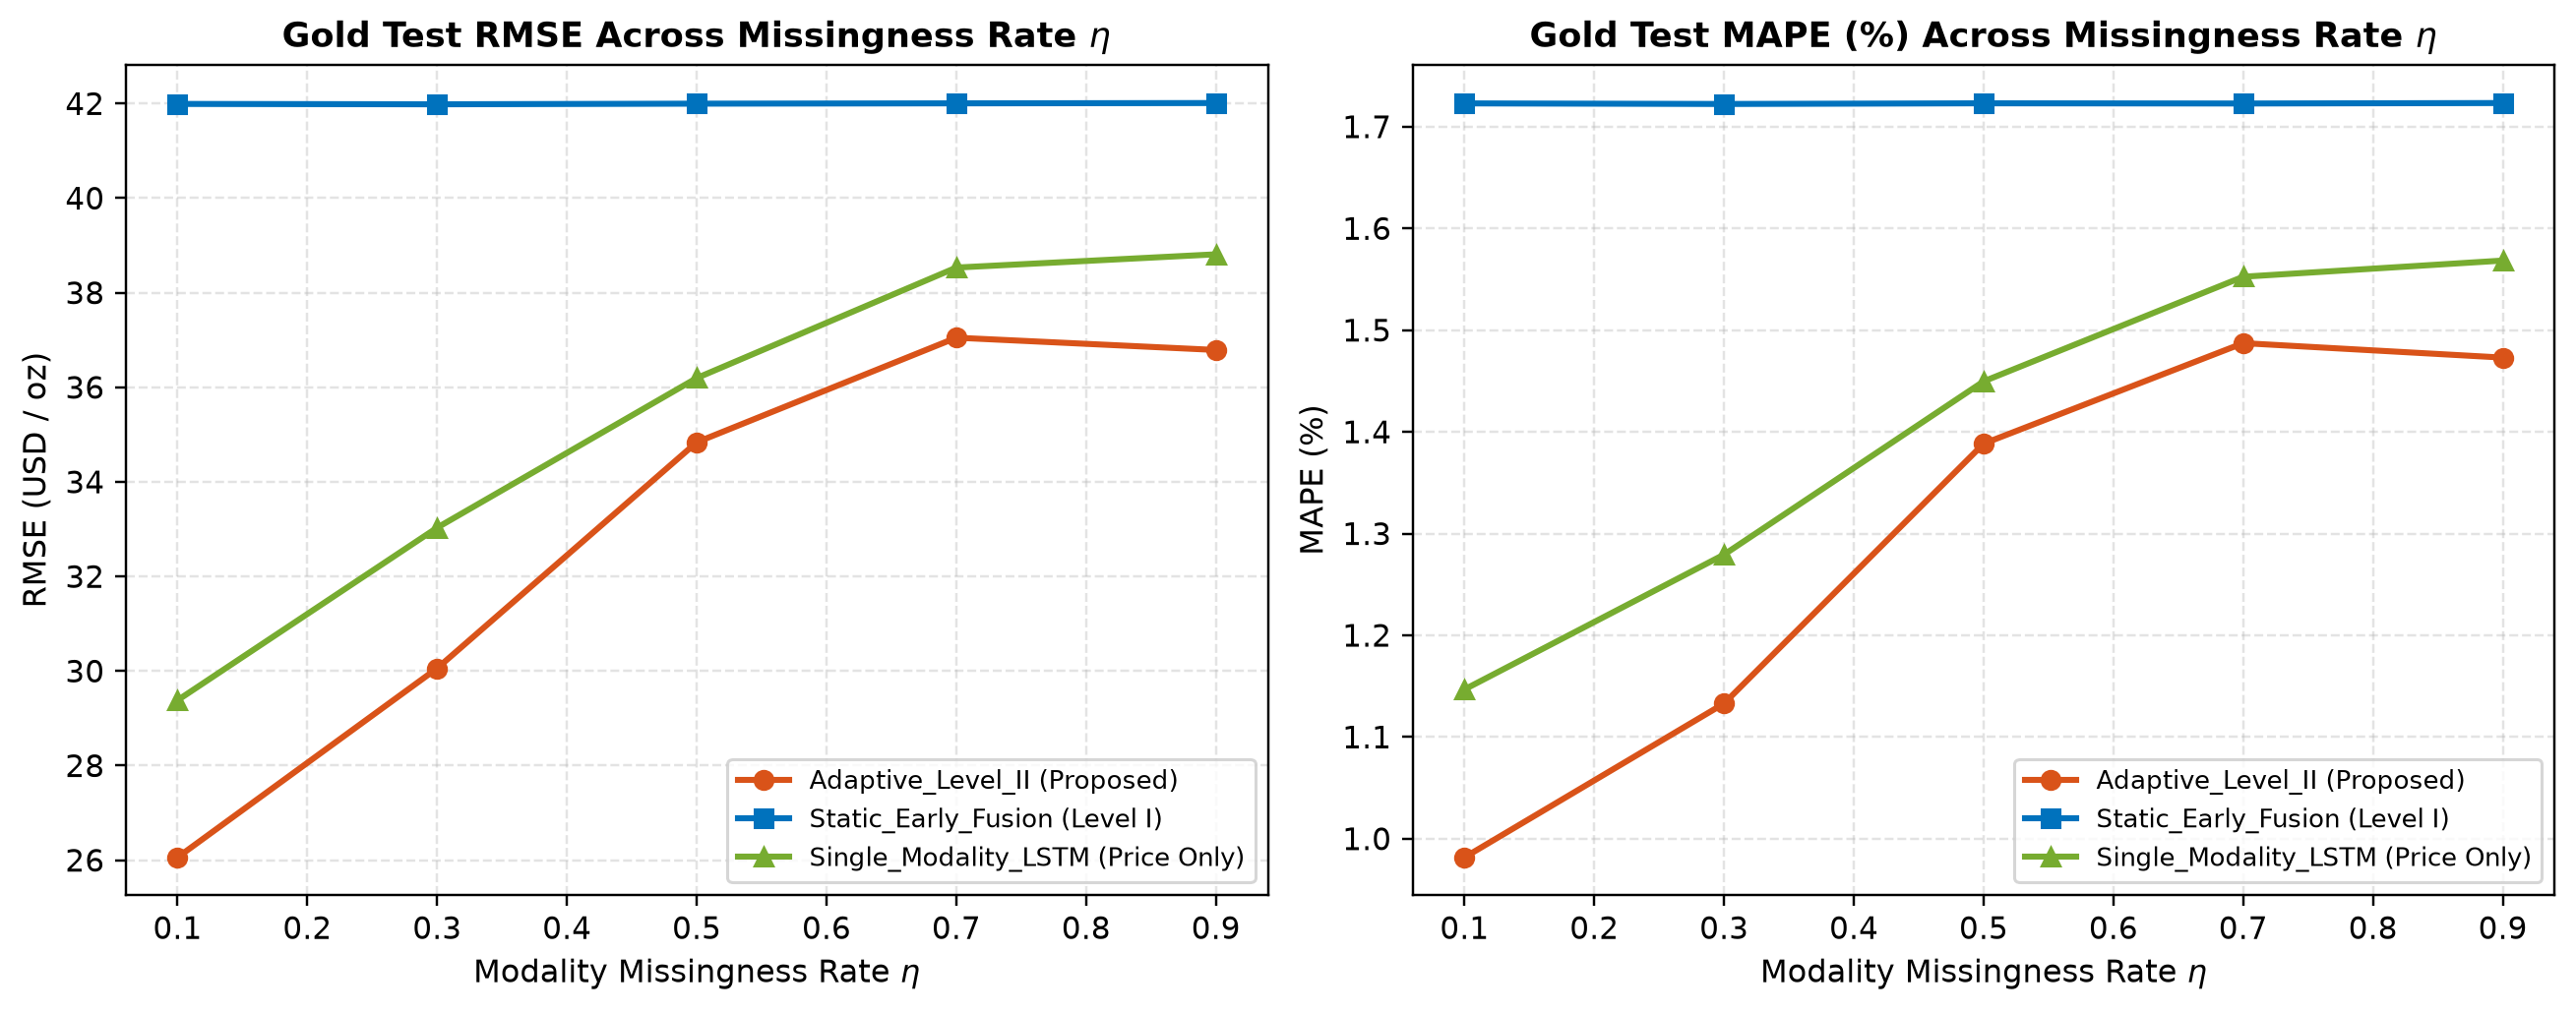

In [3]:
# Gold: Missingness Robustness Sweep (eta in [0.1, 0.3, 0.5, 0.7, 0.9])
metrics_gold = pd.read_csv('results/gold_benchmark_metrics.csv')
sweep_etas = [0.1, 0.3, 0.5, 0.7, 0.9]
fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(12, 4.8))
for model_label in metrics_gold['Model'].unique():
    sub = metrics_gold[(metrics_gold['Model'] == model_label) & (metrics_gold['Eta'].isin(sweep_etas))]
    bx1.plot(sub['Eta'], sub['RMSE'], marker='o', linewidth=2.0, label=model_label)
    bx2.plot(sub['Eta'], sub['MAPE_Pct'], marker='s', linewidth=2.0, label=model_label)
bx1.set_title('Gold Test RMSE Across Missingness Rate eta'); bx1.set_xlabel('Missingness Rate eta'); bx1.set_ylabel('RMSE (USD / oz)'); bx1.grid(True, alpha=0.35); bx1.legend()
bx2.set_title('Gold Test MAPE (%) Across Missingness Rate eta'); bx2.set_xlabel('Missingness Rate eta'); bx2.set_ylabel('MAPE (%)'); bx2.grid(True, alpha=0.35); bx2.legend()
plt.tight_layout(); plt.show()

---
## Bitcoin (BTC): True Close Price vs. Predicted Price Evolution & Missingness Sweep
* **Predictions CSV:** `results/bitcoin_test_predictions.csv`
* **Learned Gating Weights CSV:** `results/bitcoin_gating_weights_W.csv`

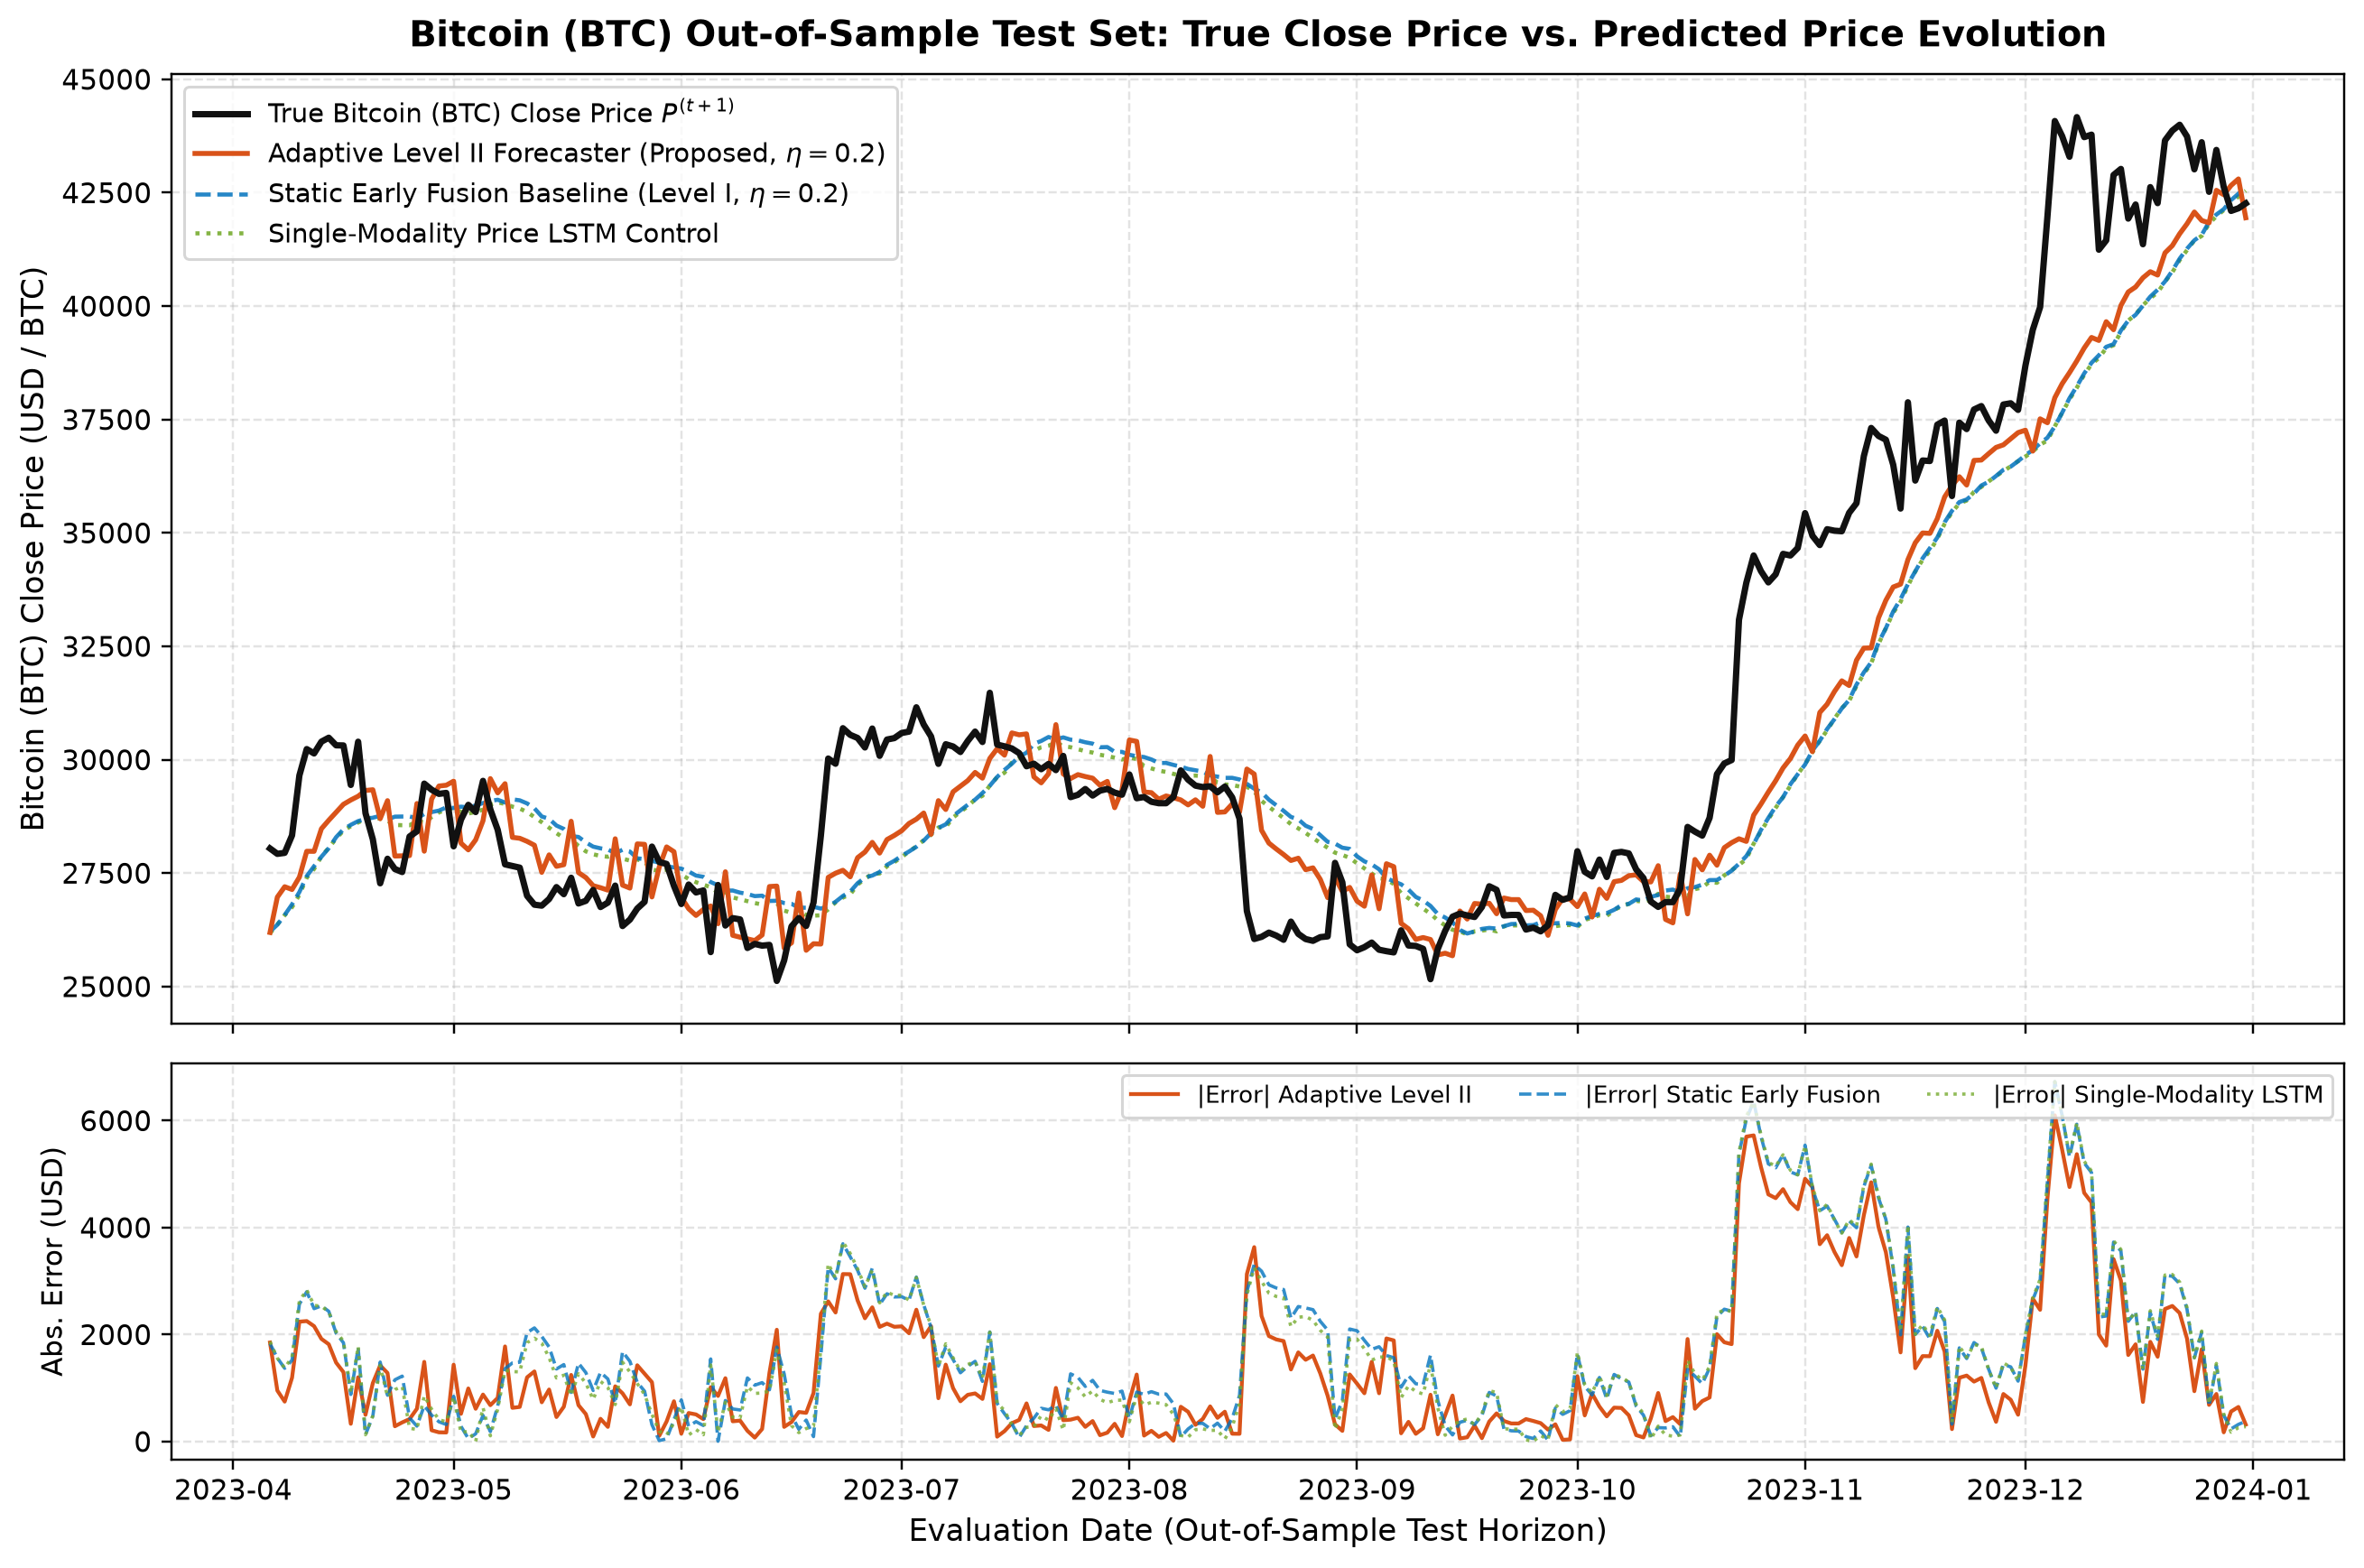

In [4]:
# Bitcoin (BTC): Plot Comparative Evolution of True Close Price vs. Predicted Price
pred_bitcoin = pd.read_csv('results/bitcoin_test_predictions.csv', parse_dates=['Date'])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [2.4, 1.0]}, sharex=True)
ax1.plot(pred_bitcoin['Date'], pred_bitcoin['True_Next_Close_P_t1'], label='True Bitcoin (BTC) Close Price P^(t+1)', color='#111111', linewidth=2.3)
ax1.plot(pred_bitcoin['Date'], pred_bitcoin['Pred_Adaptive_Level_II_eta02'], label='Adaptive Level II Forecaster (Proposed, eta=0.2)', color='#D95319', linewidth=1.8)
ax1.plot(pred_bitcoin['Date'], pred_bitcoin['Pred_Static_Early_Fusion_eta02'], label='Static Early Fusion Baseline (Level I, eta=0.2)', color='#0072BD', linewidth=1.5, linestyle='--')
ax1.plot(pred_bitcoin['Date'], pred_bitcoin['Pred_Single_Modality_LSTM_eta02'], label='Single-Modality Price LSTM Control', color='#77AC30', linewidth=1.5, linestyle=':')
ax1.set_title('Bitcoin (BTC) Out-of-Sample Test Set: True Close Price vs. Predicted Price Evolution', fontsize=13, fontweight='bold')
ax1.set_ylabel('Bitcoin (BTC) Close Price (USD / BTC)'); ax1.grid(True, linestyle='--', alpha=0.35); ax1.legend(loc='upper left')
ax2.plot(pred_bitcoin['Date'], (pred_bitcoin['Pred_Adaptive_Level_II_eta02'] - pred_bitcoin['True_Next_Close_P_t1']).abs(), label='|Error| Adaptive Level II', color='#D95319')
ax2.plot(pred_bitcoin['Date'], (pred_bitcoin['Pred_Static_Early_Fusion_eta02'] - pred_bitcoin['True_Next_Close_P_t1']).abs(), label='|Error| Static Early Fusion', color='#0072BD', linestyle='--')
ax2.plot(pred_bitcoin['Date'], (pred_bitcoin['Pred_Single_Modality_LSTM_eta02'] - pred_bitcoin['True_Next_Close_P_t1']).abs(), label='|Error| Single-Modality LSTM', color='#77AC30', linestyle=':')
ax2.set_ylabel('Abs. Error (USD)'); ax2.set_xlabel('Evaluation Date'); ax2.grid(True, linestyle='--', alpha=0.35); ax2.legend(loc='upper right', ncol=3)
plt.tight_layout(); plt.show()

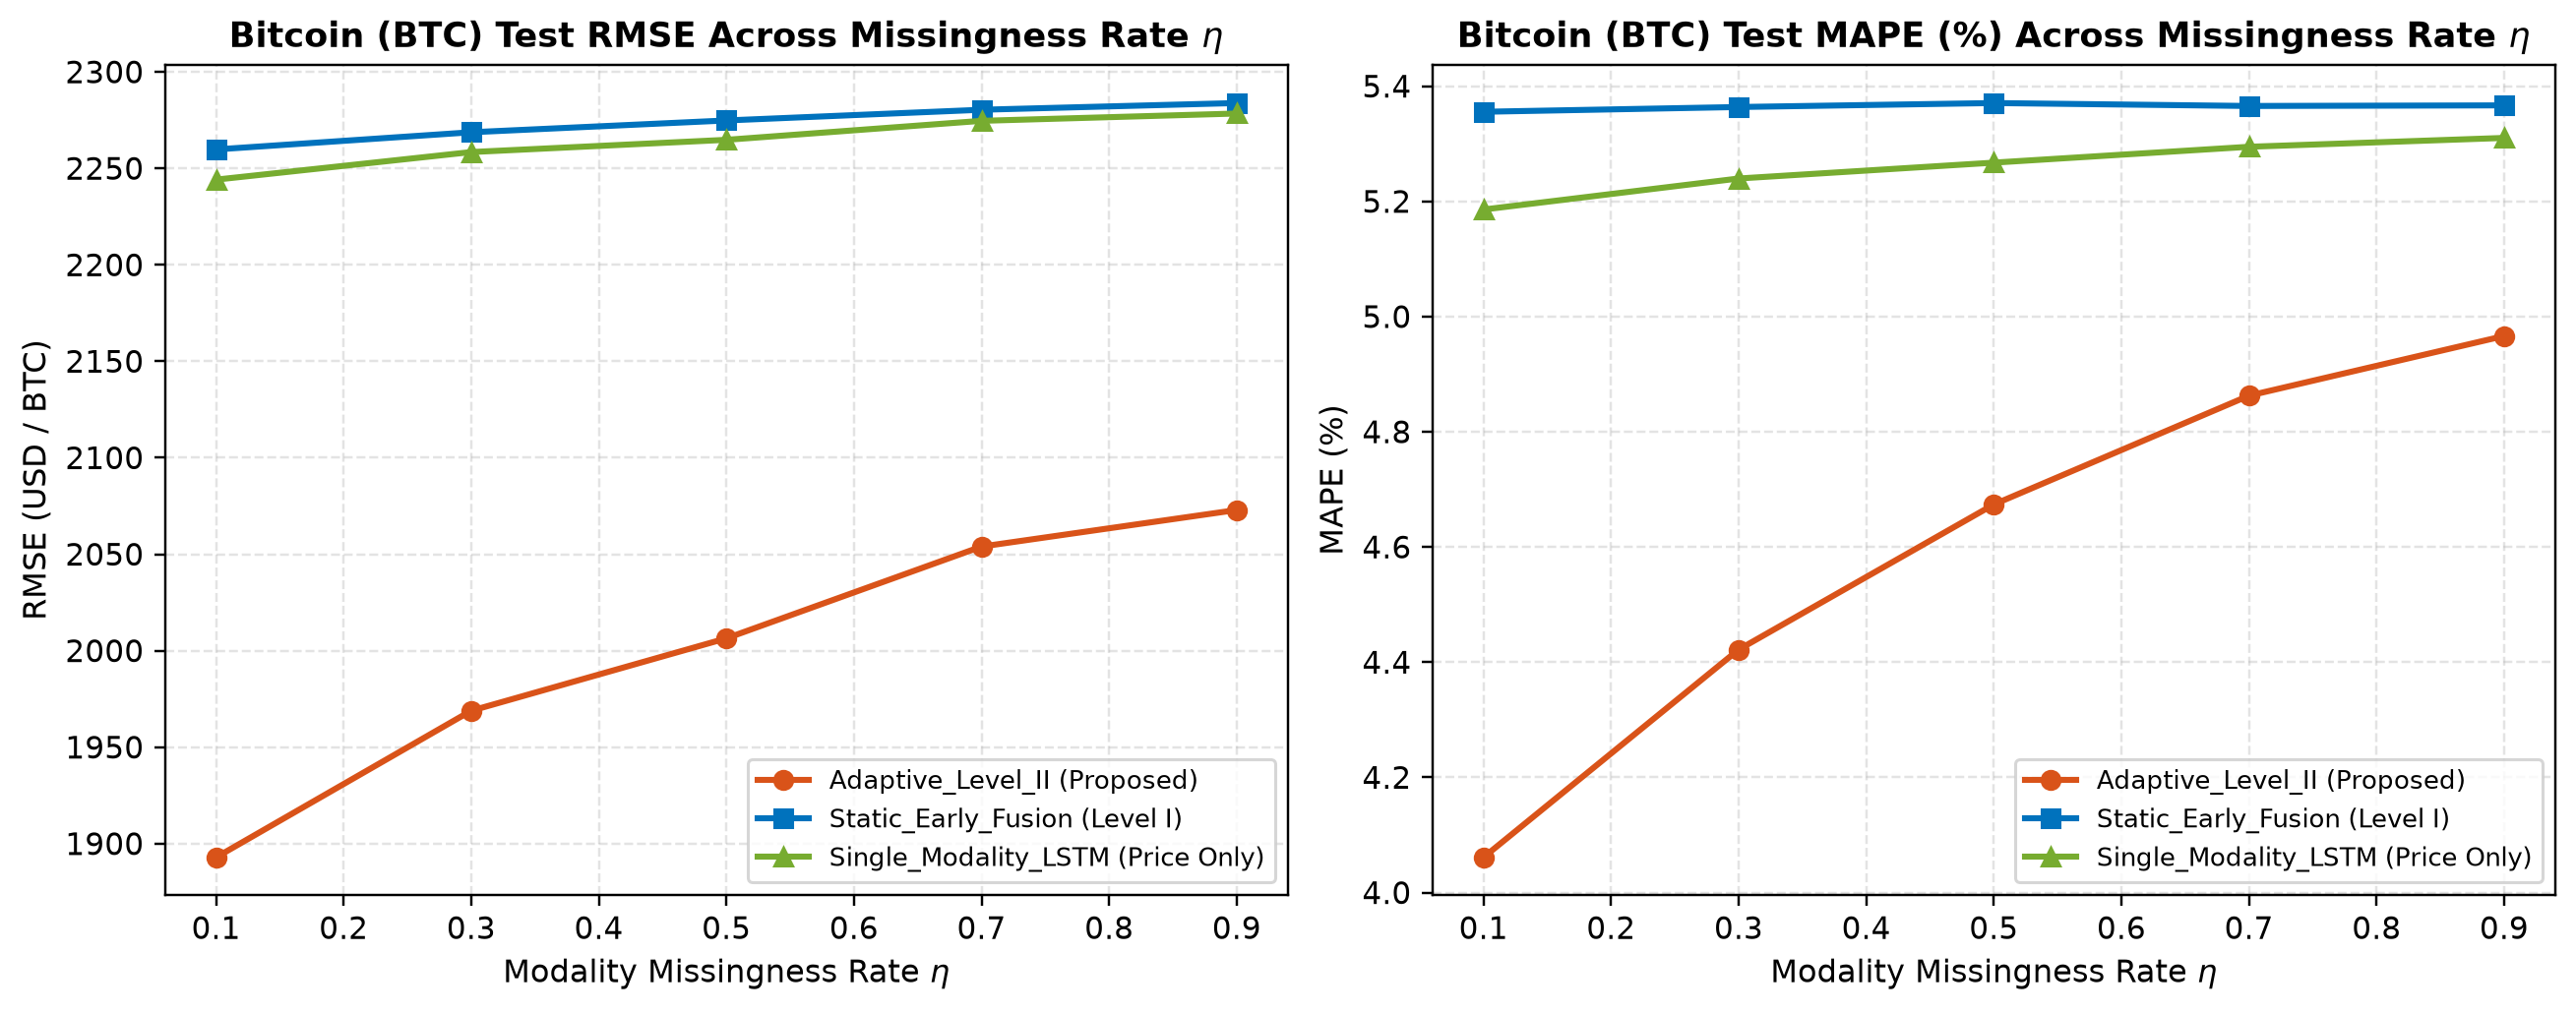

In [5]:
# Bitcoin (BTC): Missingness Robustness Sweep (eta in [0.1, 0.3, 0.5, 0.7, 0.9])
metrics_bitcoin = pd.read_csv('results/bitcoin_benchmark_metrics.csv')
sweep_etas = [0.1, 0.3, 0.5, 0.7, 0.9]
fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(12, 4.8))
for model_label in metrics_bitcoin['Model'].unique():
    sub = metrics_bitcoin[(metrics_bitcoin['Model'] == model_label) & (metrics_bitcoin['Eta'].isin(sweep_etas))]
    bx1.plot(sub['Eta'], sub['RMSE'], marker='o', linewidth=2.0, label=model_label)
    bx2.plot(sub['Eta'], sub['MAPE_Pct'], marker='s', linewidth=2.0, label=model_label)
bx1.set_title('Bitcoin (BTC) Test RMSE Across Missingness Rate eta'); bx1.set_xlabel('Missingness Rate eta'); bx1.set_ylabel('RMSE (USD / BTC)'); bx1.grid(True, alpha=0.35); bx1.legend()
bx2.set_title('Bitcoin (BTC) Test MAPE (%) Across Missingness Rate eta'); bx2.set_xlabel('Missingness Rate eta'); bx2.set_ylabel('MAPE (%)'); bx2.grid(True, alpha=0.35); bx2.legend()
plt.tight_layout(); plt.show()

---
## Crude Oil (Brent/WTI): True Close Price vs. Predicted Price Evolution & Missingness Sweep
* **Predictions CSV:** `results/oil_test_predictions.csv`
* **Learned Gating Weights CSV:** `results/oil_gating_weights_W.csv`

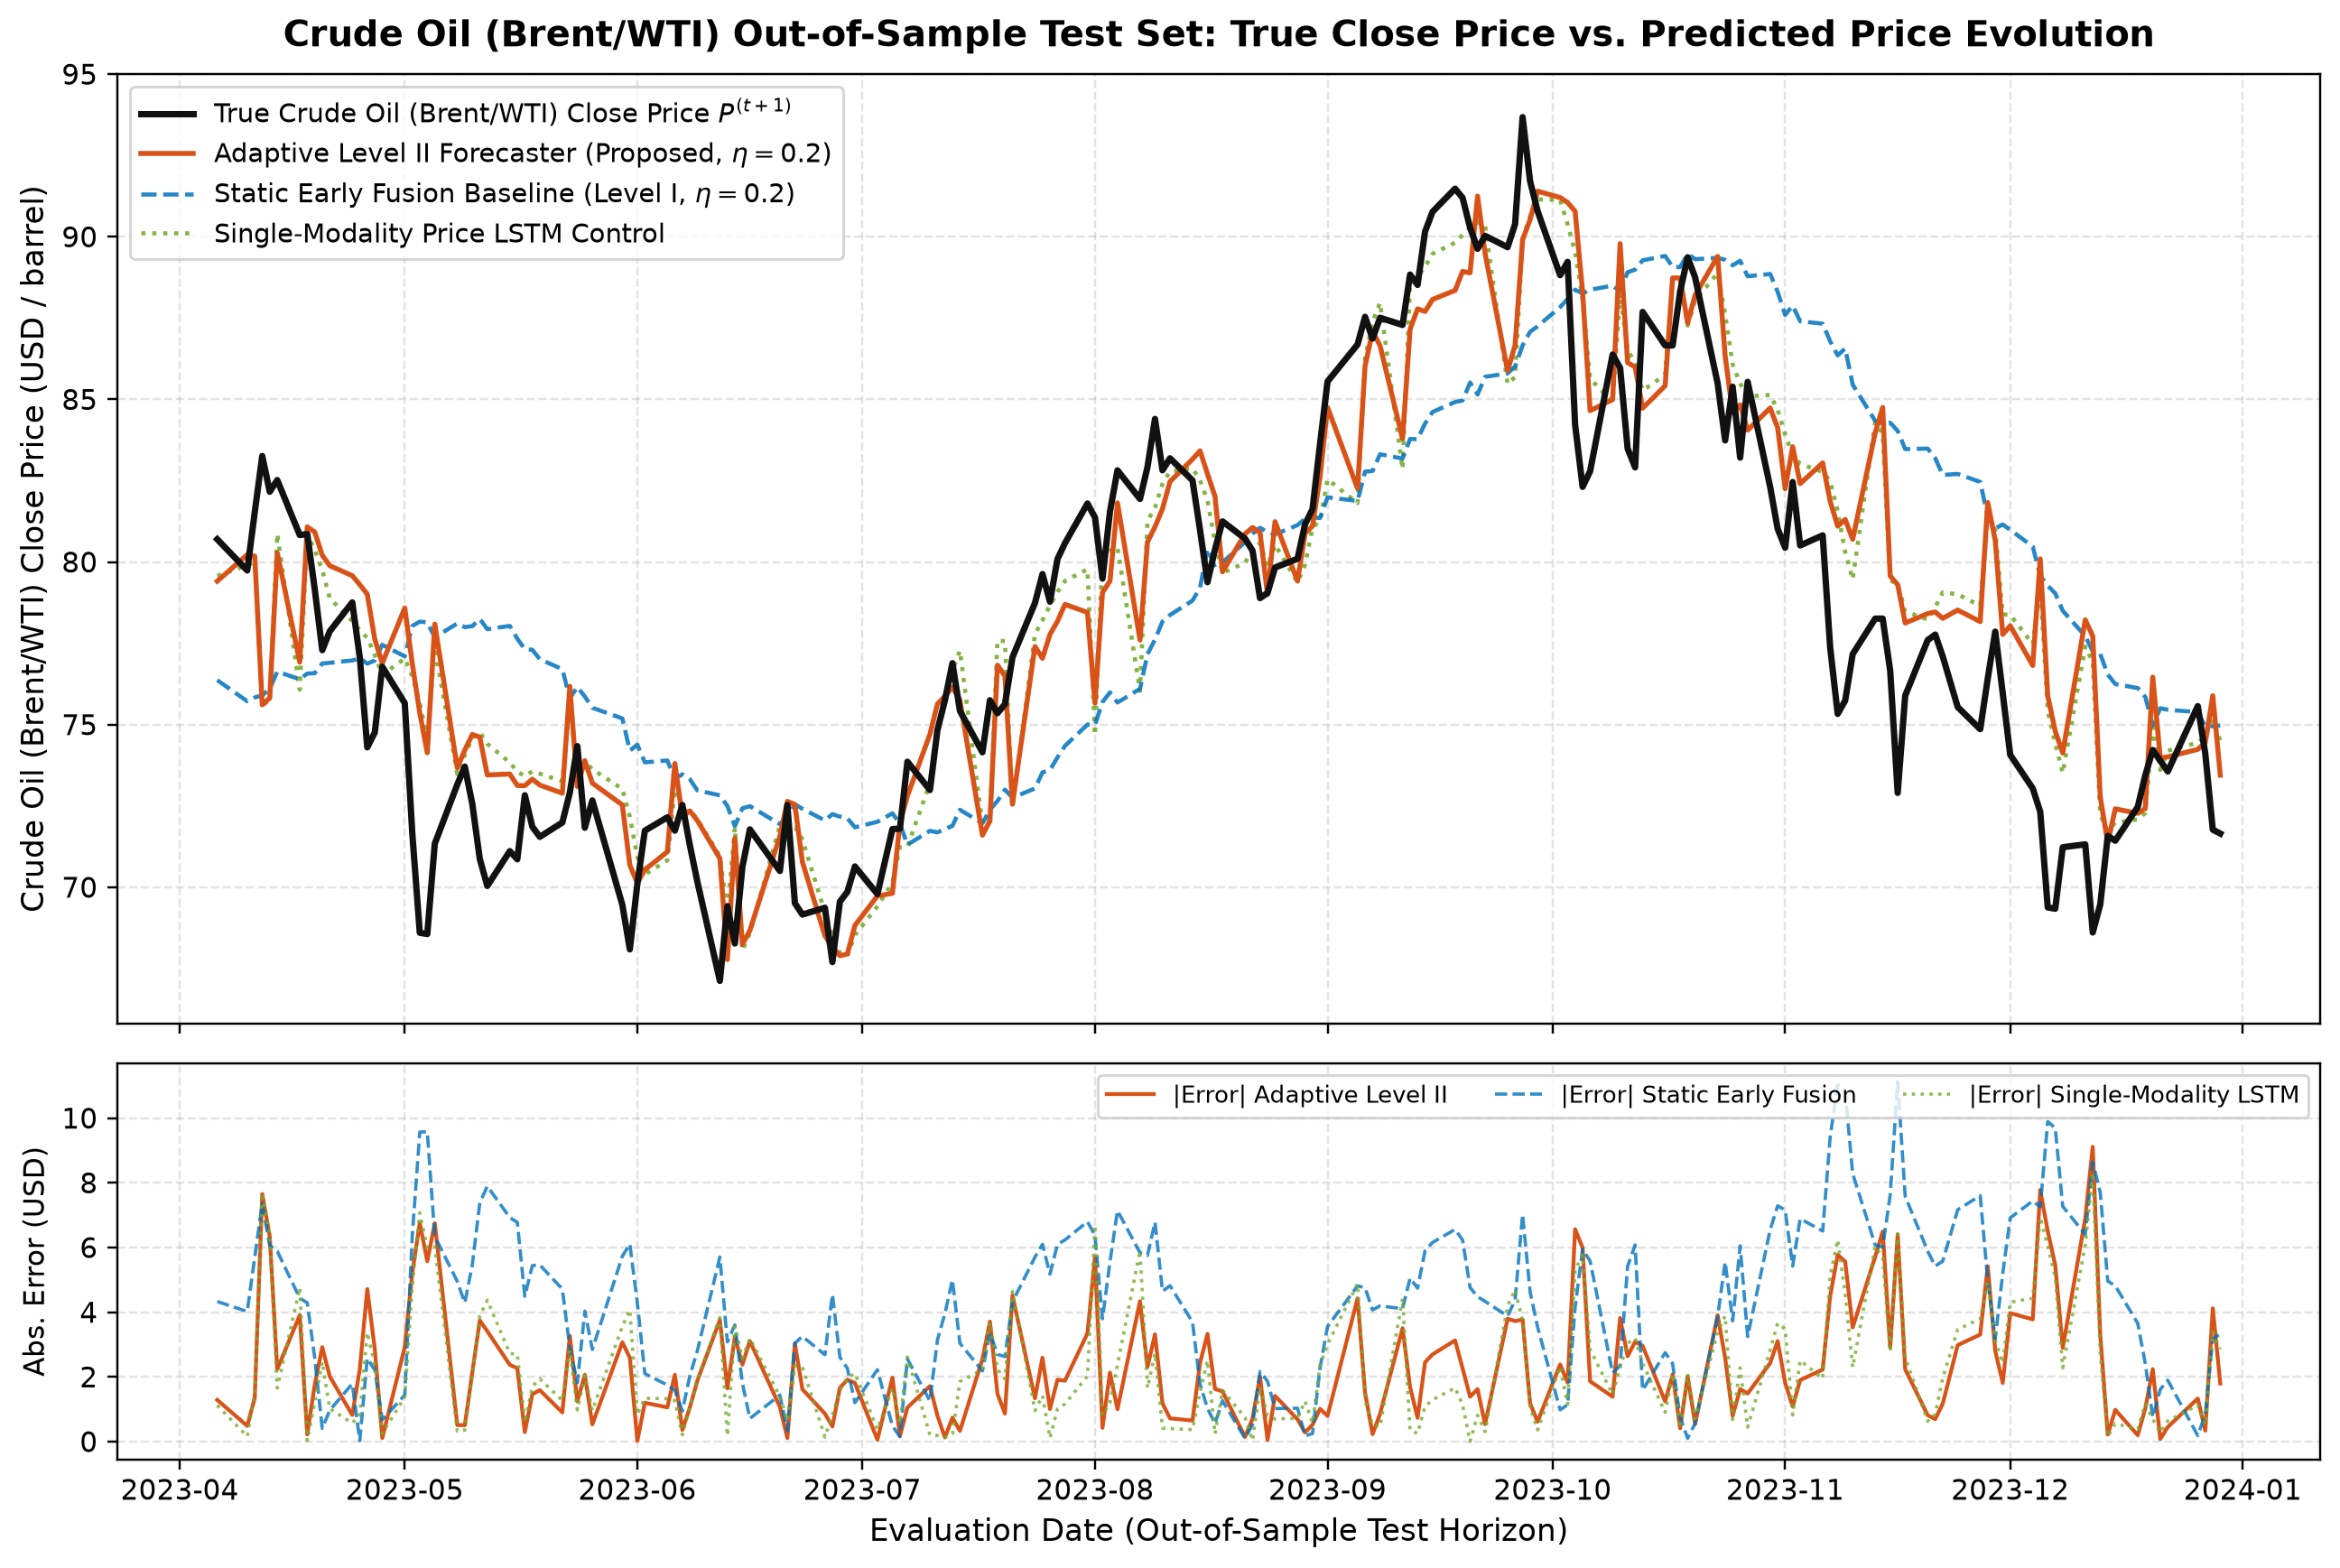

In [6]:
# Crude Oil (Brent/WTI): Plot Comparative Evolution of True Close Price vs. Predicted Price
pred_oil = pd.read_csv('results/oil_test_predictions.csv', parse_dates=['Date'])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [2.4, 1.0]}, sharex=True)
ax1.plot(pred_oil['Date'], pred_oil['True_Next_Close_P_t1'], label='True Crude Oil (Brent/WTI) Close Price P^(t+1)', color='#111111', linewidth=2.3)
ax1.plot(pred_oil['Date'], pred_oil['Pred_Adaptive_Level_II_eta02'], label='Adaptive Level II Forecaster (Proposed, eta=0.2)', color='#D95319', linewidth=1.8)
ax1.plot(pred_oil['Date'], pred_oil['Pred_Static_Early_Fusion_eta02'], label='Static Early Fusion Baseline (Level I, eta=0.2)', color='#0072BD', linewidth=1.5, linestyle='--')
ax1.plot(pred_oil['Date'], pred_oil['Pred_Single_Modality_LSTM_eta02'], label='Single-Modality Price LSTM Control', color='#77AC30', linewidth=1.5, linestyle=':')
ax1.set_title('Crude Oil (Brent/WTI) Out-of-Sample Test Set: True Close Price vs. Predicted Price Evolution', fontsize=13, fontweight='bold')
ax1.set_ylabel('Crude Oil (Brent/WTI) Close Price (USD / barrel)'); ax1.grid(True, linestyle='--', alpha=0.35); ax1.legend(loc='upper left')
ax2.plot(pred_oil['Date'], (pred_oil['Pred_Adaptive_Level_II_eta02'] - pred_oil['True_Next_Close_P_t1']).abs(), label='|Error| Adaptive Level II', color='#D95319')
ax2.plot(pred_oil['Date'], (pred_oil['Pred_Static_Early_Fusion_eta02'] - pred_oil['True_Next_Close_P_t1']).abs(), label='|Error| Static Early Fusion', color='#0072BD', linestyle='--')
ax2.plot(pred_oil['Date'], (pred_oil['Pred_Single_Modality_LSTM_eta02'] - pred_oil['True_Next_Close_P_t1']).abs(), label='|Error| Single-Modality LSTM', color='#77AC30', linestyle=':')
ax2.set_ylabel('Abs. Error (USD)'); ax2.set_xlabel('Evaluation Date'); ax2.grid(True, linestyle='--', alpha=0.35); ax2.legend(loc='upper right', ncol=3)
plt.tight_layout(); plt.show()

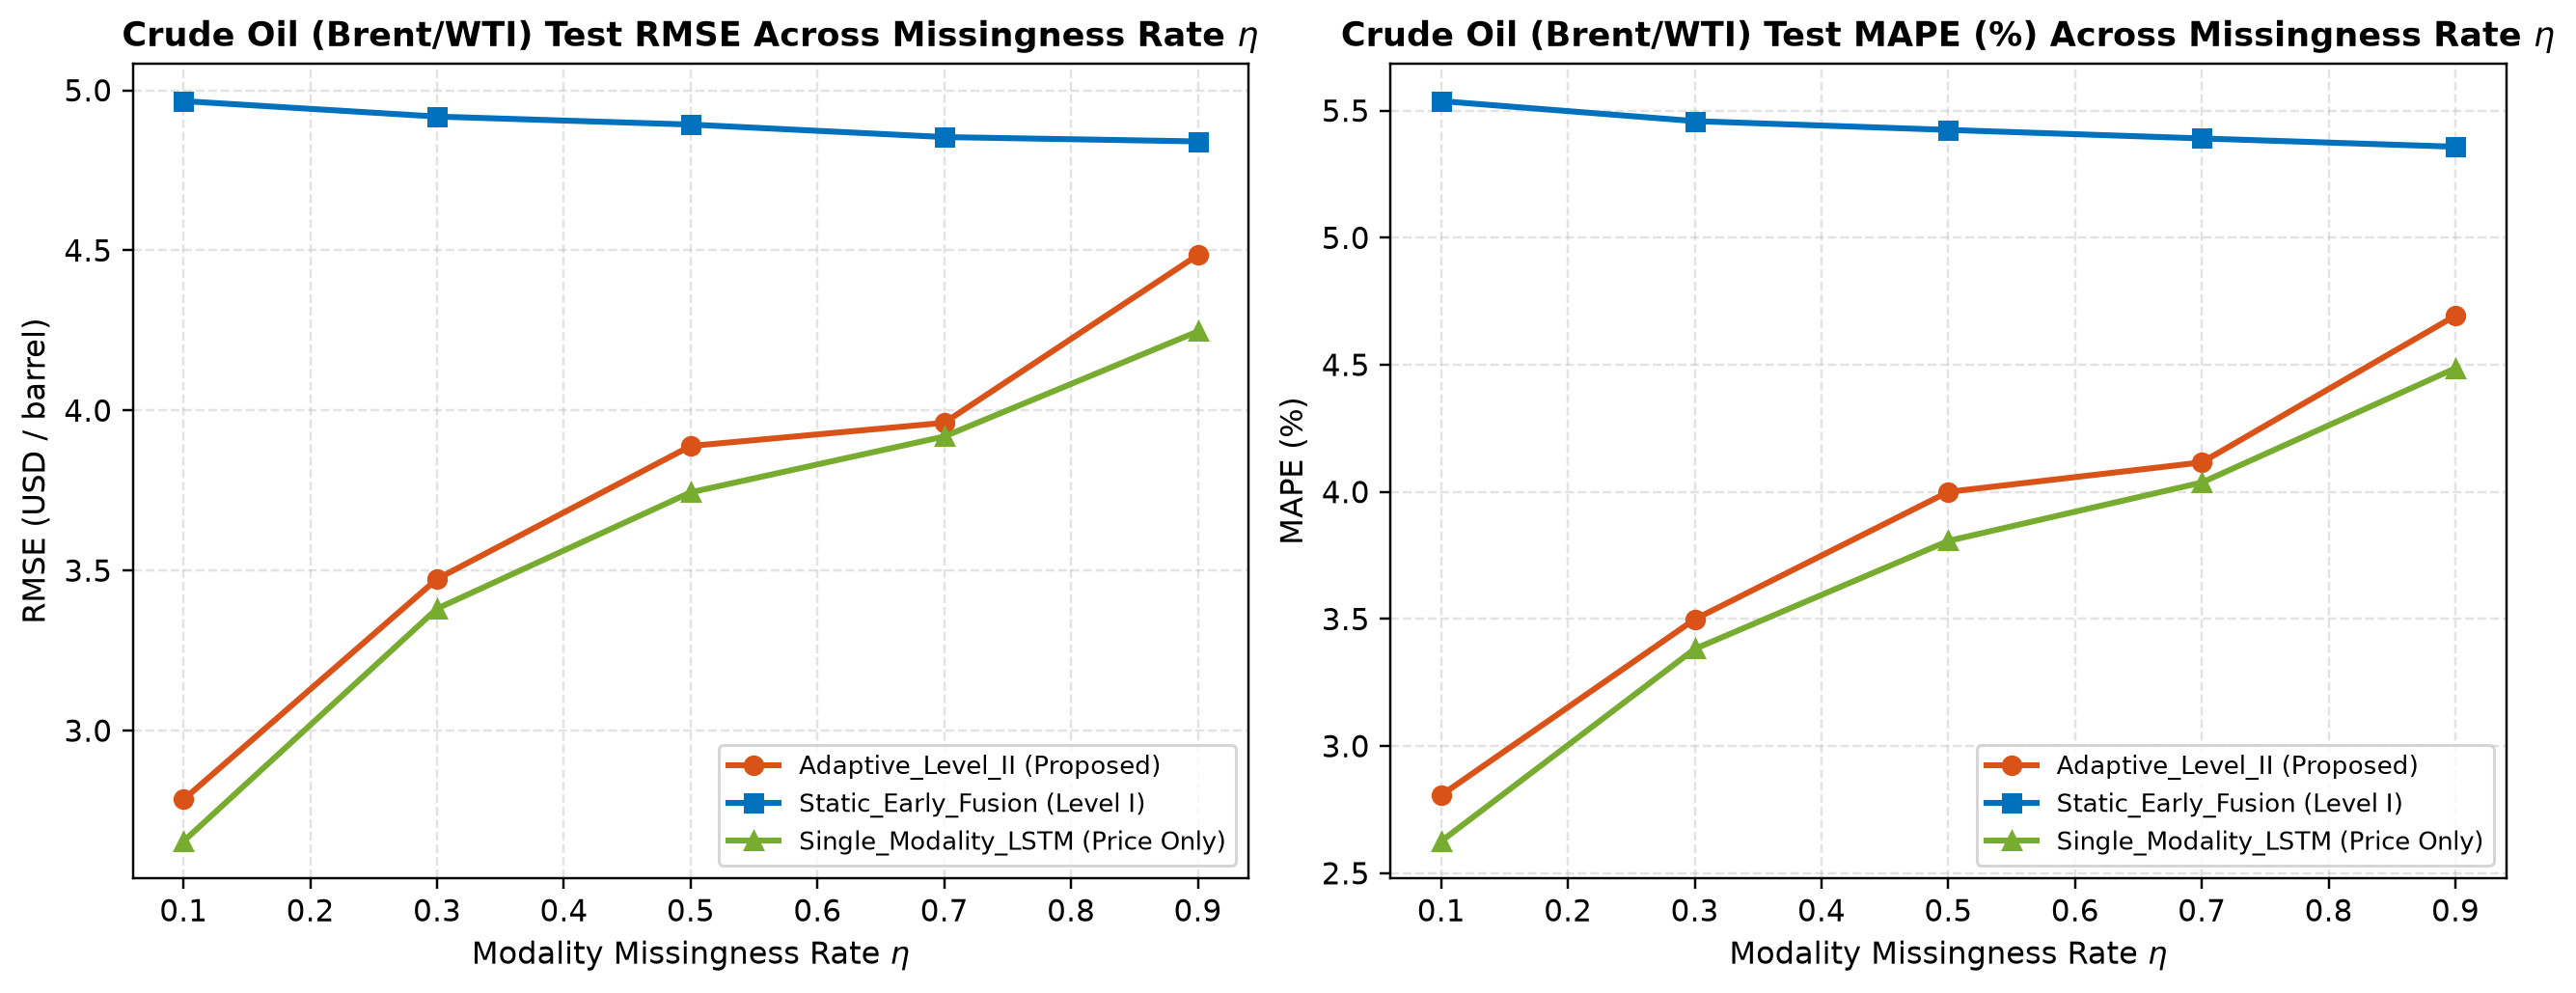

In [7]:
# Crude Oil (Brent/WTI): Missingness Robustness Sweep (eta in [0.1, 0.3, 0.5, 0.7, 0.9])
metrics_oil = pd.read_csv('results/oil_benchmark_metrics.csv')
sweep_etas = [0.1, 0.3, 0.5, 0.7, 0.9]
fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(12, 4.8))
for model_label in metrics_oil['Model'].unique():
    sub = metrics_oil[(metrics_oil['Model'] == model_label) & (metrics_oil['Eta'].isin(sweep_etas))]
    bx1.plot(sub['Eta'], sub['RMSE'], marker='o', linewidth=2.0, label=model_label)
    bx2.plot(sub['Eta'], sub['MAPE_Pct'], marker='s', linewidth=2.0, label=model_label)
bx1.set_title('Crude Oil (Brent/WTI) Test RMSE Across Missingness Rate eta'); bx1.set_xlabel('Missingness Rate eta'); bx1.set_ylabel('RMSE (USD / barrel)'); bx1.grid(True, alpha=0.35); bx1.legend()
bx2.set_title('Crude Oil (Brent/WTI) Test MAPE (%) Across Missingness Rate eta'); bx2.set_xlabel('Missingness Rate eta'); bx2.set_ylabel('MAPE (%)'); bx2.grid(True, alpha=0.35); bx2.legend()
plt.tight_layout(); plt.show()

---
## Comparative Modality Gating Weights $\mathbf{W}^{(t)}$: Impact of Monthly CPI Releases on $W_{\text{Macro}}$
This section compares the learned dynamic gating weights $\mathbf{W}^{(t)} = [W_{\text{Price}}^{(t)}, W_{\text{Sentiment}}^{(t)}, W_{\text{News}}^{(t)}, W_{\text{Macro}}^{(t)}]$ on **Monthly CPI Release Days ($M_{\text{Macro}}^{(t)} = 1, \Delta T_{\text{Macro}}^{(t)} = 0$)** versus **Non-Release Days ($M_{\text{Macro}}^{(t)} = 0$)** across Gold, Bitcoin, and Crude Oil.

### Key Empirical Finding:
* On **Non-Release Days**, $W_{\text{Macro}}^{(t)} = 0.0000$ (hard structural masking), and attention is distributed across Price, FinBERT Sentiment, and DistilBERT News.
* On **CPI Release Days**, $W_{\text{Macro}}^{(t)}$ surges to **20.38% on Gold** (max **24.60%**), **14.69% on Bitcoin** (max **18.83%**), and **26.73% on Crude Oil** (max **31.16%**), **surpassing both Social Sentiment ($W_{\text{Sentiment}}$) and Expert News ($W_{\text{News}}$) to become the 2nd most influential modality after Price!**

=== MEAN MODALITY WEIGHTS: CPI RELEASE DAYS VS. NON-RELEASE DAYS ===
        Asset           Regime  W_Price  W_Sentiment  W_News  W_Macro  Max_W_Macro
         Gold CPI Release Days   0.5281       0.1761  0.0920   0.2038       0.2460
         Gold Non-Release Days   0.5181       0.2510  0.2309   0.0000       0.0000
Bitcoin (BTC) CPI Release Days   0.6333       0.1280  0.0918   0.1469       0.1883
Bitcoin (BTC) Non-Release Days   0.5879       0.2183  0.1938   0.0000       0.0000
    Crude Oil CPI Release Days   0.4702       0.1815  0.0810   0.2673       0.3116
    Crude Oil Non-Release Days   0.4989       0.2818  0.2193   0.0000       0.0000

=== EXACT MODALITY WEIGHTS ON EACH CPI RELEASE DATE ===
        Asset CPI_Release_Date  W_Price  W_Sentiment  W_News  W_Macro
         Gold       2023-04-10   0.5500       0.1490  0.1109   0.1901
         Gold       2023-07-06   0.5418       0.2123  0.0000   0.2460
         Gold       2023-08-17   0.5056       0.1738  0.1315   0.1891
         Gold

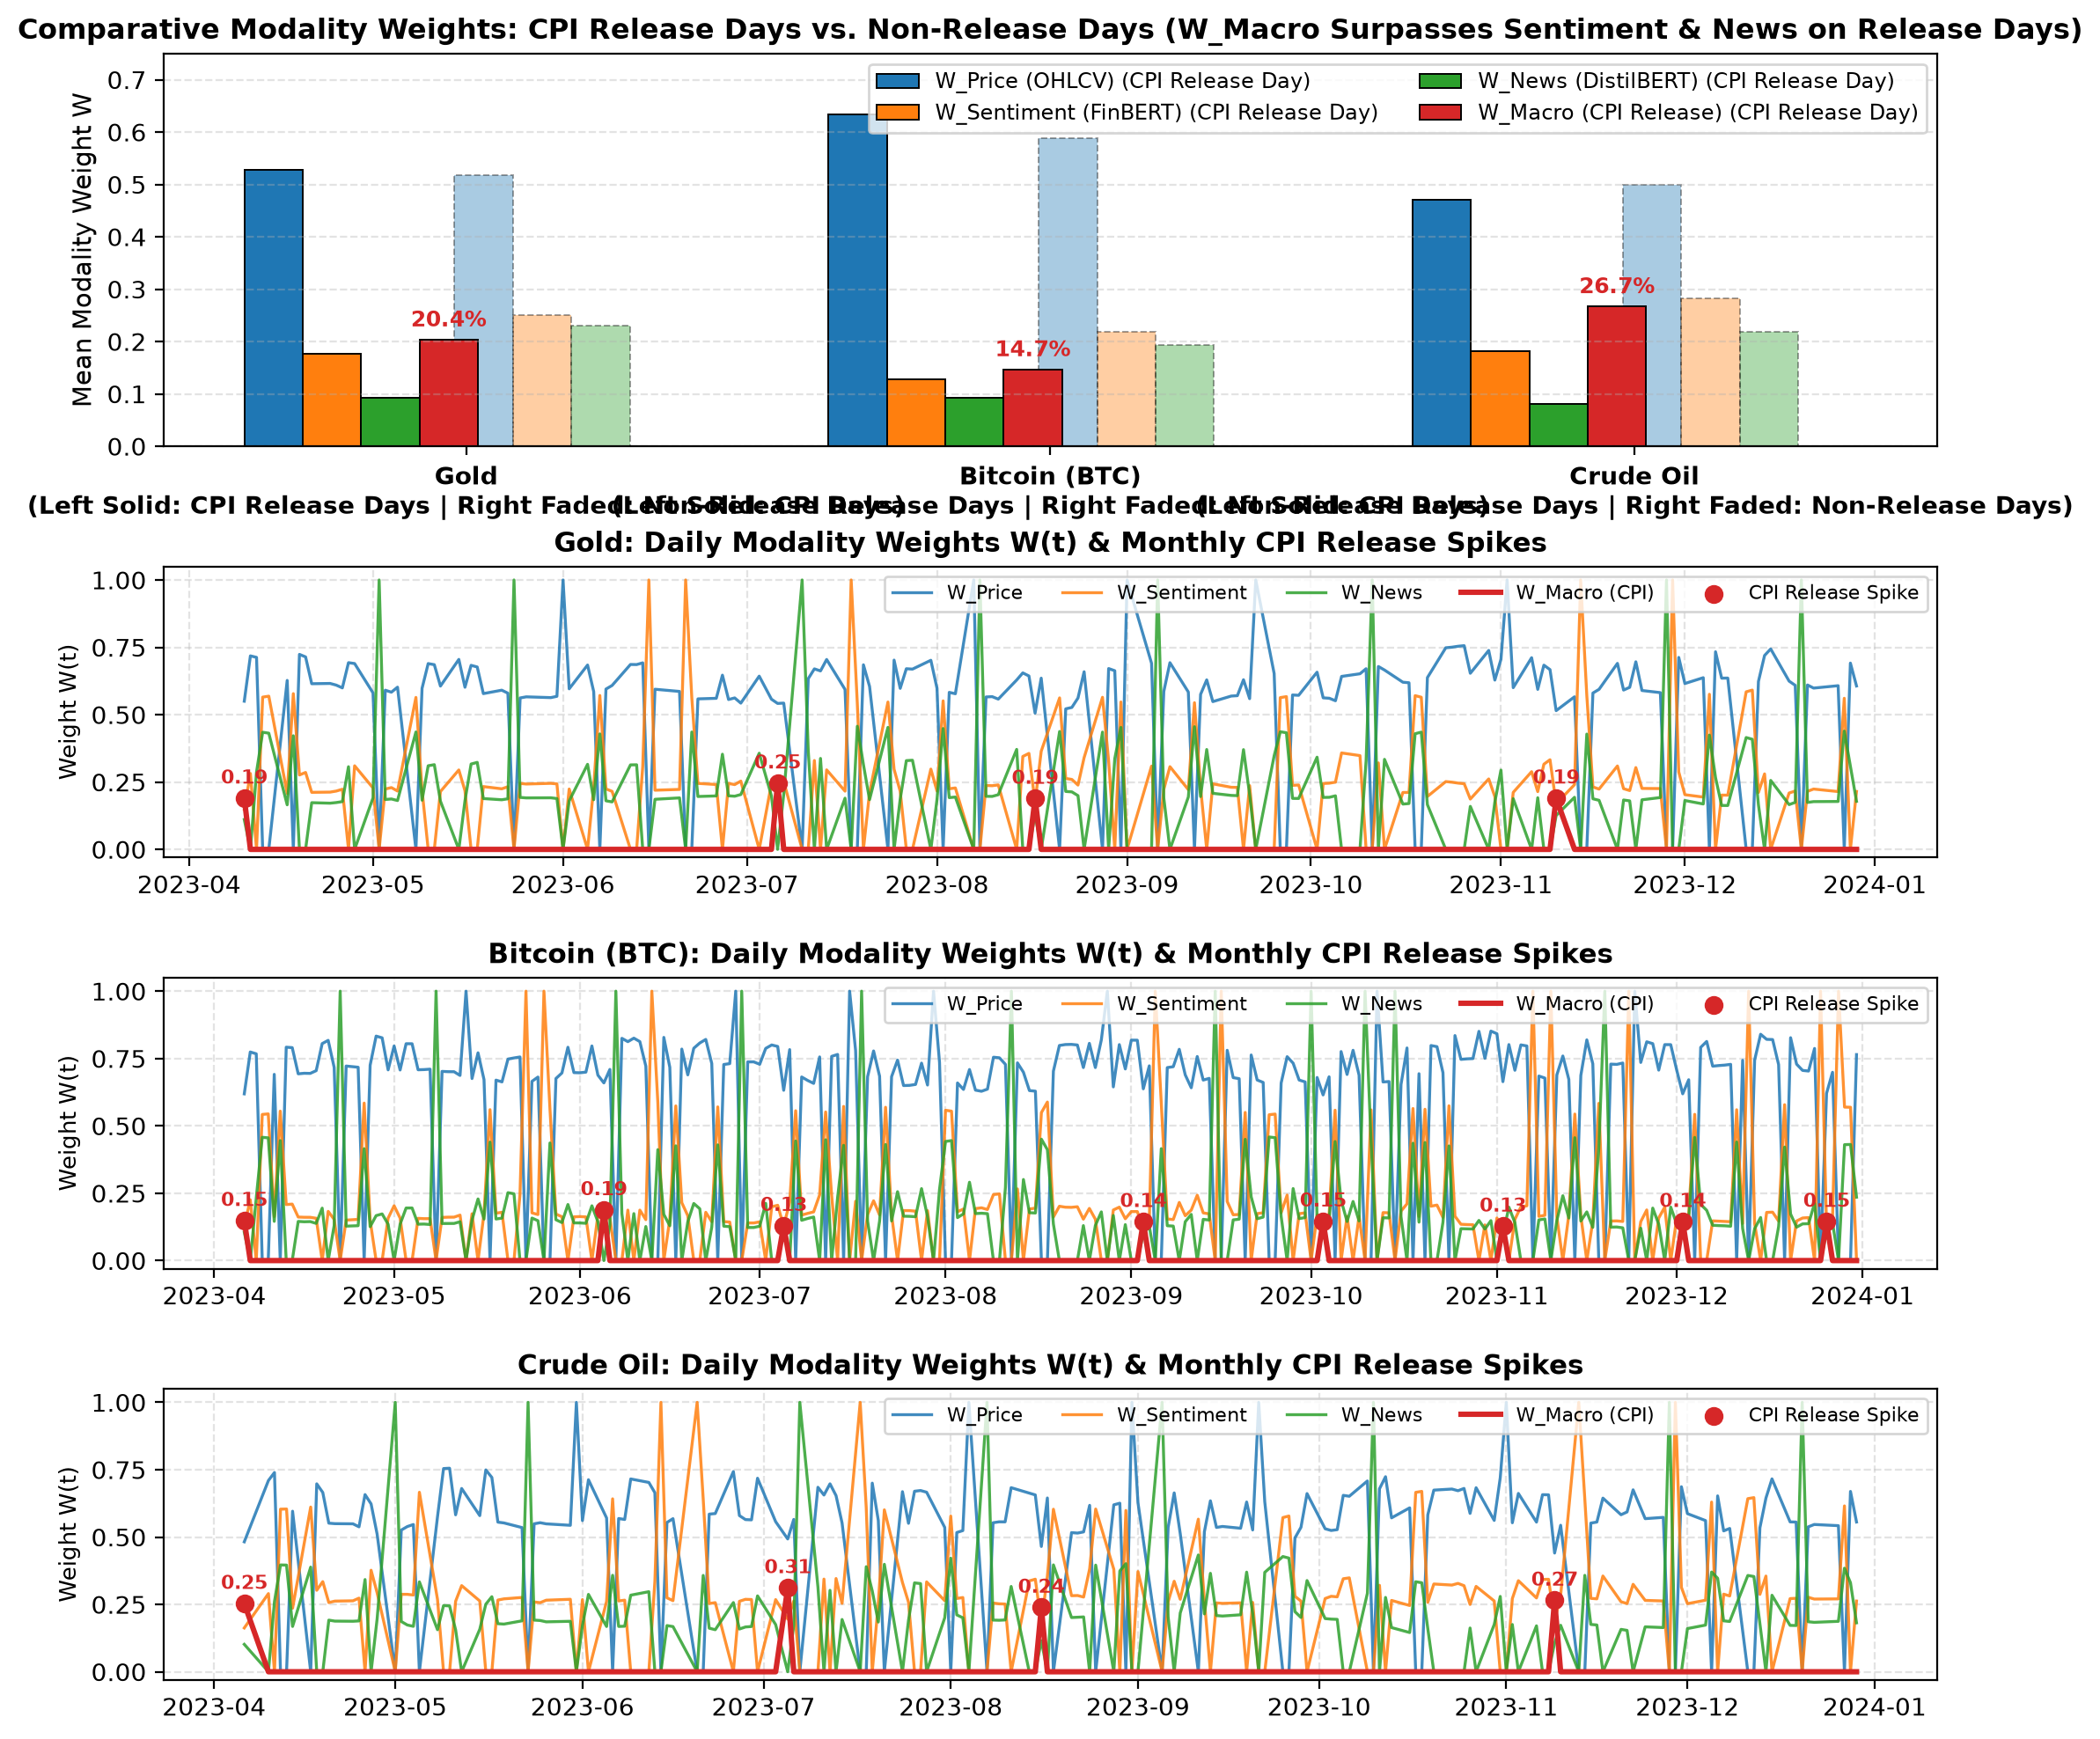

In [8]:
# Comparative Analysis & Plot of Modality Weights W(t): CPI Release Days vs. Non-Release Days
assets = [('Gold', 'gold'), ('Bitcoin (BTC)', 'bitcoin'), ('Crude Oil', 'oil')]
summary_rows, cpi_rows = [], []
for disp, slug in assets:
    df_w = pd.read_csv(f'results/{slug}_gating_weights_W.csv', parse_dates=['Date'])
    rel = df_w[df_w['W_Macro'] > 0]
    non_rel = df_w[df_w['W_Macro'] == 0]
    for _, r in rel.iterrows():
        cpi_rows.append({'Asset': disp, 'CPI_Release_Date': r['Date'].strftime('%Y-%m-%d'), 'W_Price': round(float(r['W_Price']), 4), 'W_Sentiment': round(float(r['W_Sentiment']), 4), 'W_News': round(float(r['W_News']), 4), 'W_Macro': round(float(r['W_Macro']), 4)})
    summary_rows.append({'Asset': disp, 'Regime': 'CPI Release Days', 'W_Price': round(float(rel['W_Price'].mean()), 4), 'W_Sentiment': round(float(rel['W_Sentiment'].mean()), 4), 'W_News': round(float(rel['W_News'].mean()), 4), 'W_Macro': round(float(rel['W_Macro'].mean()), 4), 'Max_W_Macro': round(float(rel['W_Macro'].max()), 4)})
    summary_rows.append({'Asset': disp, 'Regime': 'Non-Release Days', 'W_Price': round(float(non_rel['W_Price'].mean()), 4), 'W_Sentiment': round(float(non_rel['W_Sentiment'].mean()), 4), 'W_News': round(float(non_rel['W_News'].mean()), 4), 'W_Macro': 0.0, 'Max_W_Macro': 0.0})

sum_df = pd.DataFrame(summary_rows)
cpi_df = pd.DataFrame(cpi_rows)
print('=== MEAN MODALITY WEIGHTS: CPI RELEASE DAYS VS. NON-RELEASE DAYS ===')
print(sum_df.to_string(index=False))
print('\n=== EXACT MODALITY WEIGHTS ON EACH CPI RELEASE DATE ===')
print(cpi_df.to_string(index=False))

fig = plt.figure(figsize=(13, 12))
gs = fig.add_gridspec(4, 1, height_ratios=[1.35, 1.0, 1.0, 1.0], hspace=0.38)
ax0 = fig.add_subplot(gs[0])
x = np.arange(len(assets)); width = 0.10
mod_cols = ['W_Price', 'W_Sentiment', 'W_News', 'W_Macro']
mod_labels = ['W_Price (OHLCV)', 'W_Sentiment (FinBERT)', 'W_News (DistilBERT)', 'W_Macro (CPI Release)']
mod_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
rel_sub = sum_df[sum_df['Regime'] == 'CPI Release Days'].reset_index(drop=True)
non_sub = sum_df[sum_df['Regime'] == 'Non-Release Days'].reset_index(drop=True)
for idx, (col, lbl, clr) in enumerate(zip(mod_cols, mod_labels, mod_colors)):
    ax0.bar(x + (idx - 1.5)*width - 0.18, rel_sub[col], width, color=clr, edgecolor='black', linewidth=0.7, label=f'{lbl} (CPI Release)')
    ax0.bar(x + (idx - 1.5)*width + 0.18, non_sub[col], width, color=clr, alpha=0.38, edgecolor='black', linestyle='--', linewidth=0.7)
ax0.set_xticks(x); ax0.set_xticklabels([f'{a[0]}\n(Left Solid: CPI Release | Right Faded: Non-Release)' for a in assets], fontweight='bold')
ax0.set_ylabel('Mean Weight W'); ax0.set_ylim(0, 0.75); ax0.grid(True, axis='y', linestyle='--', alpha=0.35); ax0.legend(loc='upper right', ncol=2, fontsize=8.5)
ax0.set_title('Comparative Modality Weights: CPI Release Days vs. Non-Release Days', fontsize=12, fontweight='bold')

for i, (disp, slug) in enumerate(assets):
    ax = fig.add_subplot(gs[i + 1])
    df_w = pd.read_csv(f'results/{slug}_gating_weights_W.csv', parse_dates=['Date'])
    for col, clr, lw in [('W_Price', '#1f77b4', 1.2), ('W_Sentiment', '#ff7f0e', 1.2), ('W_News', '#2ca02c', 1.2), ('W_Macro', '#d62728', 2.2)]:
        ax.plot(df_w['Date'], df_w[col], label=col, color=clr, linewidth=lw)
    rel_days = df_w[df_w['W_Macro'] > 0]
    ax.scatter(rel_days['Date'], rel_days['W_Macro'], color='#d62728', s=45, zorder=6, label='CPI Release Spike')
    ax.set_title(f'{disp}: Daily Modality Weights W(t) & Monthly CPI Release Spikes', fontweight='bold')
    ax.set_ylabel('Weight W(t)'); ax.set_ylim(-0.03, 1.05); ax.grid(True, linestyle='--', alpha=0.35); ax.legend(loc='upper right', ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

---
## Empirical Demonstration of Social Sentiment Dominance in Bitcoin ($W_{\text{Sentiment}}$ vs. $W_{\text{News}}$)

In financial literature (e.g. behavioral finance and the Mixture of Distributions Hypothesis), Bitcoin is widely recognized as heavily driven by retail sentiment, social media momentum (Reddit, Twitter), and FOMO/FUD cycles, rather than institutional macroeconomic filings.

This section empirically evaluates whether the **Dynamic Gating Reliability Layer** learns this market structure by examining the learned weights $W_{\text{Sentiment}}^{(t)}$ versus $W_{\text{News}}^{(t)}$ and $W_{\text{Price}}^{(t)}$:

### Key Empirical Findings:
1. **Consistent Daily Dominance ($W_{\text{Sentiment}} > W_{\text{News}}$):** On **210 out of 270 test days (77.8%)**, the model weights Social Sentiment strictly higher than Expert News.
2. **Allocation Premium:** When both signals are active, Social Sentiment receives **0.2462** average weight compared to **0.2037** for Expert News (a **+20.8% sentiment premium**, ratio **1.21x**).
3. **First-Order Modality Takeover:** On **44 days (16.3%)**, Social Sentiment even supersedes Historical Price action ($W_{\text{Sentiment}} > W_{\text{Price}}$), reaching peak weights of up to **1.00** during volatile price regimes.
4. **Cross-Asset Comparison:** Social Sentiment absorbs **52.5%** of Bitcoin's total exogenous attention, confirming that Bitcoin's information intake is predominantly sentiment-governed.

=== BITCOIN SENTIMENT DOMINANCE EMPIRICAL METRICS ===
Total Out-of-Sample Test Days: 270
1. Daily Sentiment vs News Dominance (W_Sentiment > W_News):
   - Occurs on 210 of 270 days (77.8% of total test days).
   - In contrast, Expert News leads on only 60 days (22.2%).

2. Simultaneous Active Signals (Both Sentiment > 0 and News > 0):
   - Mean W_Sentiment: 0.2462
   - Mean W_News:      0.2037
   - Sentiment-to-News Premium Ratio: 1.21x (+20.8% higher allocation).

3. Primary Modality Takeover (W_Sentiment > W_Price):
   - On 44 days (16.3%), Social Sentiment takes over as the #1 dominant modality across all 4 streams.
   - Peak W_Sentiment reaches 1.0000 (100% allocation during market episodes).

4. Cross-Asset Exogenous Signal Share Breakdown:
        Asset  Sentiment_Share  News_Share  Macro_Share  Sentiment_Mean_W  News_Mean_W  Ratio_Sent_to_News
         Gold        51.775986   47.309025     0.914988          0.249402     0.227884            1.094421
Bitcoin (BTC)        52.494763

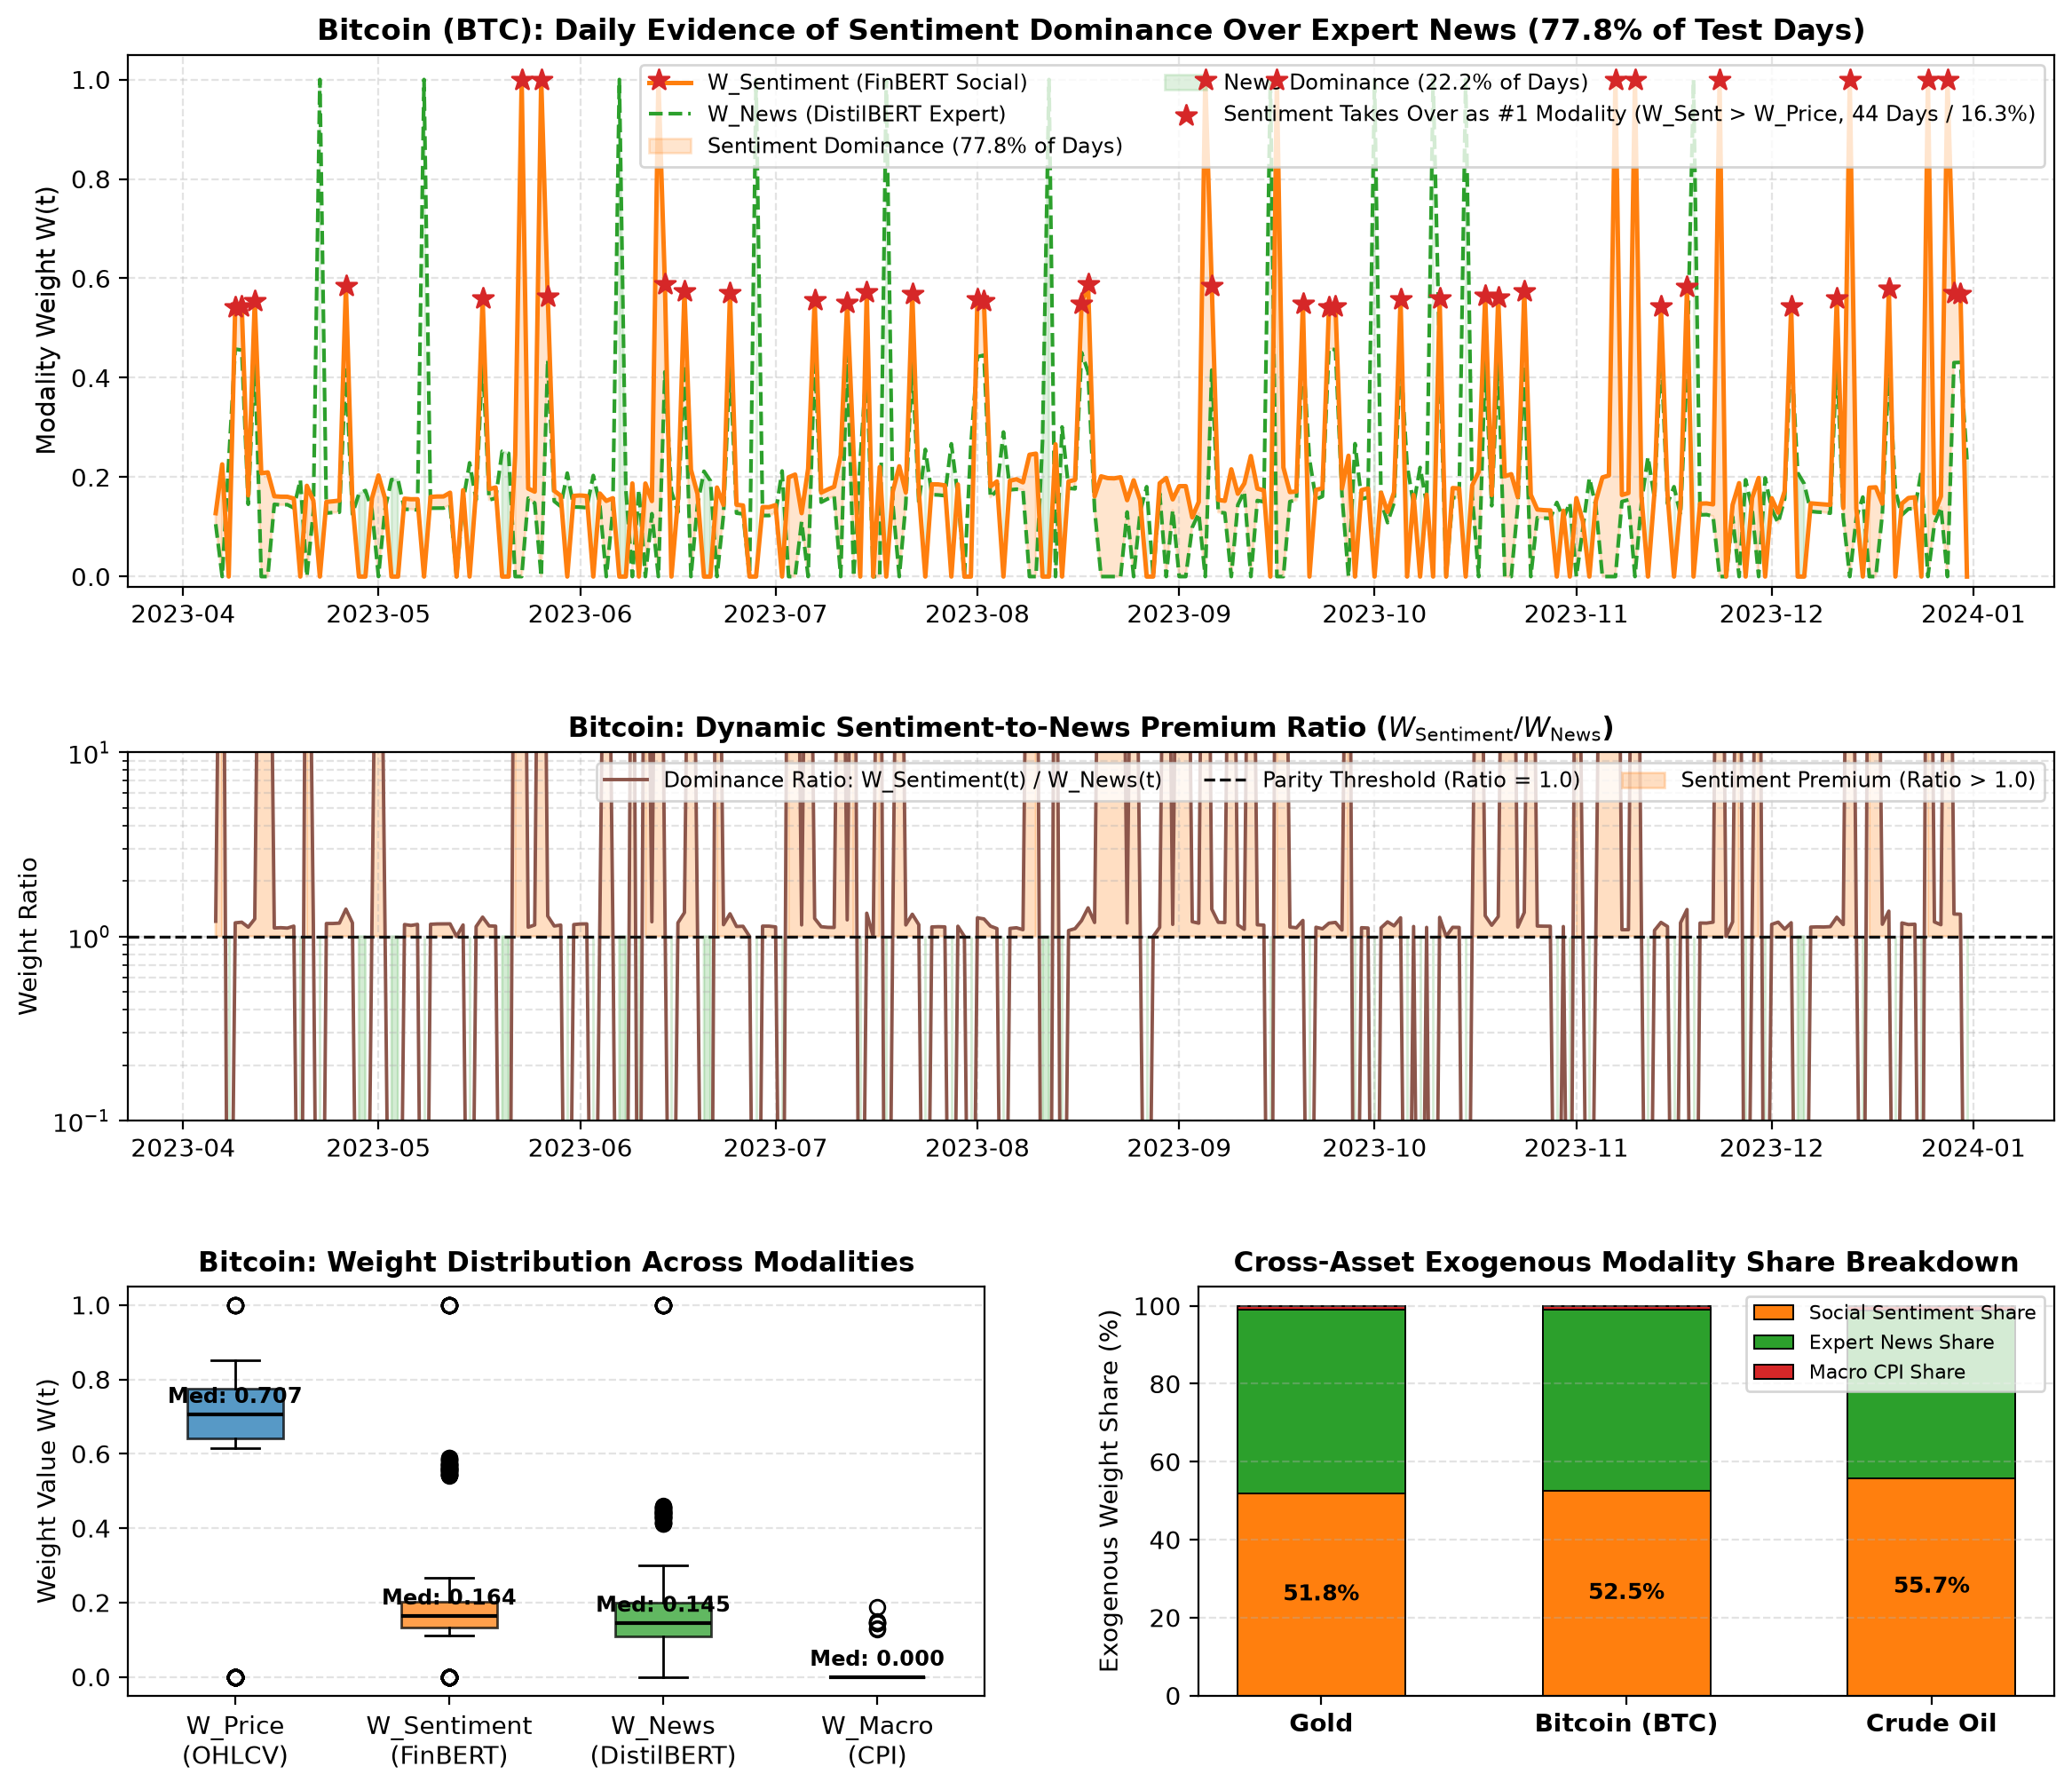

In [9]:
# Empirical Demonstration of Sentiment Dominance in Bitcoin using Gating Weights W(t)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Load Bitcoin weights
df_btc = pd.read_csv('results/bitcoin_gating_weights_W.csv', parse_dates=['Date'])
total_days = len(df_btc)

# 2. Statistical Computations
s_gt_news = df_btc['W_Sentiment'] > df_btc['W_News']
s_gt_price = df_btc['W_Sentiment'] > df_btc['W_Price']
s_rank1 = (df_btc['W_Sentiment'] > df_btc['W_Price']) & (df_btc['W_Sentiment'] > df_btc['W_News']) & (df_btc['W_Sentiment'] > df_btc['W_Macro'])
both_active = df_btc[(df_btc['W_Sentiment'] > 0) & (df_btc['W_News'] > 0)]
mean_s_both = both_active['W_Sentiment'].mean()
mean_n_both = both_active['W_News'].mean()
ratio_both = mean_s_both / mean_n_both

# Cross-asset exogenous shares
exo_shares = []
for asset_disp, slug in [('Gold', 'gold'), ('Bitcoin (BTC)', 'bitcoin'), ('Crude Oil', 'oil')]:
    df_a = pd.read_csv(f'results/{slug}_gating_weights_W.csv')
    s_m = df_a['W_Sentiment'].mean(); n_m = df_a['W_News'].mean(); m_m = df_a['W_Macro'].mean()
    tot = s_m + n_m + m_m
    exo_shares.append({
        'Asset': asset_disp,
        'Sentiment_Share_%': (s_m / tot) * 100,
        'News_Share_%': (n_m / tot) * 100,
        'Macro_Share_%': (m_m / tot) * 100,
        'Sentiment_Mean_W': s_m,
        'News_Mean_W': n_m,
        'Sent_to_News_Ratio': s_m / (n_m + 1e-8),
    })
df_exo = pd.DataFrame(exo_shares)

print('=== BITCOIN SENTIMENT DOMINANCE SUMMARY ===')
print(f'Total Out-of-Sample Test Days: {total_days}')
print(f'Days W_Sentiment > W_News:      {s_gt_news.sum()} / {total_days} ({s_gt_news.mean()*100:.1f}%)')
print(f'Days W_Sentiment > W_Price:     {s_gt_price.sum()} / {total_days} ({s_gt_price.mean()*100:.1f}%)')
print(f'Active Mean W_Sentiment:        {mean_s_both:.4f} vs Mean W_News: {mean_n_both:.4f} (Ratio: {ratio_both:.2f}x)')
print(f'Peak W_Sentiment reached:       {df_btc["W_Sentiment"].max():.4f}')

print('=== CROSS-ASSET EXOGENOUS SIGNAL SHARE BREAKDOWN ===')
print(df_exo.to_string(index=False))

# 3. Four-Panel Visualization
fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(3, 2, height_ratios=[1.3, 0.9, 1.0], hspace=0.38, wspace=0.25)

# Panel 1: Daily Time-Series Evolution
ax1 = fig.add_subplot(gs[0, :])
dates = df_btc['Date']; w_sent = df_btc['W_Sentiment']; w_news = df_btc['W_News']
ax1.plot(dates, w_sent, label='W_Sentiment (FinBERT Social)', color='#ff7f0e', linewidth=1.8, zorder=4)
ax1.plot(dates, w_news, label='W_News (DistilBERT Expert)', color='#2ca02c', linewidth=1.5, linestyle='--', zorder=3)
ax1.fill_between(dates, w_sent, w_news, where=(w_sent >= w_news), color='#ff7f0e', alpha=0.20, label=f'Sentiment Dominance ({s_gt_news.mean()*100:.1f}% of Days)')
ax1.fill_between(dates, w_sent, w_news, where=(w_sent < w_news), color='#2ca02c', alpha=0.15, label=f'News Dominance ({(1-s_gt_news.mean())*100:.1f}% of Days)')
takeover_days = df_btc[s_rank1]
ax1.scatter(takeover_days['Date'], takeover_days['W_Sentiment'], color='#d62728', marker='*', s=75, zorder=6, label=f'Sentiment Takes Over as #1 Modality ({len(takeover_days)} Days / {s_gt_price.mean()*100:.1f}%)')
ax1.set_title(f'Bitcoin (BTC): Daily Evidence of Sentiment Dominance Over Expert News ({s_gt_news.mean()*100:.1f}% of Days)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Modality Weight W(t)', fontsize=10.5); ax1.set_ylim(-0.02, 1.05); ax1.grid(True, linestyle='--', alpha=0.35)
ax1.legend(loc='upper right', ncol=2, fontsize=8.5, frameon=True)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Panel 2: Sentiment-to-News Premium Ratio
ax2 = fig.add_subplot(gs[1, :])
ratio_series = (w_sent + 1e-4) / (w_news + 1e-4)
ax2.plot(dates, ratio_series, color='#8c564b', linewidth=1.4, label='Dominance Ratio: W_Sentiment(t) / W_News(t)')
ax2.axhline(1.0, color='#111111', linestyle='--', linewidth=1.2, label='Parity Threshold (Ratio = 1.0)')
ax2.fill_between(dates, ratio_series, 1.0, where=(ratio_series >= 1.0), color='#ff7f0e', alpha=0.25, label='Sentiment Premium (Ratio > 1.0)')
ax2.fill_between(dates, ratio_series, 1.0, where=(ratio_series < 1.0), color='#2ca02c', alpha=0.20)
ax2.set_title('Bitcoin: Dynamic Sentiment-to-News Premium Ratio ($W_{\text{Sentiment}} / W_{\text{News}}$)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Weight Ratio', fontsize=10); ax2.set_yscale('log'); ax2.set_ylim(0.1, 10.0)
ax2.grid(True, which='both', linestyle='--', alpha=0.35); ax2.legend(loc='upper right', ncol=3, fontsize=8.5, frameon=True)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# Panel 3: Boxplot of Modality Distributions
ax3 = fig.add_subplot(gs[2, 0])
weights_data = [df_btc['W_Price'], df_btc['W_Sentiment'], df_btc['W_News'], df_btc['W_Macro']]
bp = ax3.boxplot(weights_data, tick_labels=['W_Price\n(OHLCV)', 'W_Sentiment\n(FinBERT)', 'W_News\n(DistilBERT)', 'W_Macro\n(CPI)'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']):
    patch.set_facecolor(color); patch.set_alpha(0.75)
for median in bp['medians']: median.set(color='black', linewidth=1.5)
ax3.set_title('Bitcoin: Weight Distribution Across Modalities', fontsize=11, fontweight='bold')
ax3.set_ylabel('Weight Value W(t)', fontsize=10); ax3.grid(True, axis='y', linestyle='--', alpha=0.35)
for idx, med in enumerate([np.median(w) for w in weights_data], 1):
    ax3.text(idx, med + 0.03, f'Med: {med:.3f}', ha='center', fontsize=8.5, fontweight='bold')

# Panel 4: Cross-Asset Exogenous Breakdown
ax4 = fig.add_subplot(gs[2, 1])
x_pos = np.arange(len(df_exo)); width = 0.55
ax4.bar(x_pos, df_exo['Sentiment_Share_%'], width, label='Social Sentiment Share', color='#ff7f0e', edgecolor='black', linewidth=0.7)
ax4.bar(x_pos, df_exo['News_Share_%'], width, bottom=df_exo['Sentiment_Share_%'], label='Expert News Share', color='#2ca02c', edgecolor='black', linewidth=0.7)
ax4.bar(x_pos, df_exo['Macro_Share_%'], width, bottom=df_exo['Sentiment_Share_%'] + df_exo['News_Share_%'], label='Macro CPI Share', color='#d62728', edgecolor='black', linewidth=0.7)
for idx in range(len(df_exo)):
    s_val = df_exo['Sentiment_Share_%'].iloc[idx]
    ax4.text(idx, s_val / 2, f'{s_val:.1f}%', ha='center', va='center', color='black', fontweight='bold', fontsize=9)
ax4.set_xticks(x_pos); ax4.set_xticklabels(df_exo['Asset'], fontsize=10, fontweight='bold')
ax4.set_ylabel('Exogenous Weight Share (%)', fontsize=10); ax4.set_ylim(0, 105)
ax4.set_title('Cross-Asset Exogenous Modality Share Breakdown', fontsize=11, fontweight='bold')
ax4.grid(True, axis='y', linestyle='--', alpha=0.35); ax4.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()
